&nbsp;

# lncRNA Annotation Servey

- RNACentral & QuickGO のリソースを使用して、今回特定した transcript list のうち、どの程度アノテーションがついているかを確認するための notebook
- エンリッチメント解析ができない、使えないとはいえ、Gene Ontology のリソースが使えないわけではないので、以下の観点に基づいて調べてみる

&nbsp;

1. どの程度の lncRNA が Gene Ontology にアノテーションされているのか？
2. どのような Gene Ontology の term にアノテーションされているのか？
3. どのような evidence でアノテーションされているのか？
4. semantic similarity で見ると、どのような特徴があるのか？

In [1]:
import os
import datetime
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import polars as pl
from IPython.display import display


pl.Config.set_fmt_str_lengths(200)
pl.Config.set_tbl_rows(2)
pl.Config.set_tbl_cols(100)
os.environ["POLARS_MAX_THREADS"] = "16"

In [2]:
quickgo_9606_rna_annotation = pl.read_csv(
    "../../Data/Database/QuickGO/QuickGO_9606_onlyRNA_v20260905.tsv",
    separator="\t",
    n_threads=16
).with_columns(
    # Remove the species suffix from RNAcentral IDs (URS..._9606 -> URS...)
    pl.col("GENE PRODUCT ID").str.strip_suffix("_9606")
).rename(
    {
        "GENE PRODUCT ID": "RNACentral_ID"
    }
)

quickgo_9606_rna_annotation_rnacentral = quickgo_9606_rna_annotation.filter(
    pl.col("ASSIGNED BY") == "RNAcentral"
)

quickgo_9606_rna_annotation_other = quickgo_9606_rna_annotation.filter(
    pl.col("ASSIGNED BY") != "RNAcentral"
)

display(quickgo_9606_rna_annotation_rnacentral)
display(quickgo_9606_rna_annotation_other)


GENE PRODUCT DB,RNACentral_ID,SYMBOL,QUALIFIER,GO TERM,GO NAME,ECO ID,GO EVIDENCE CODE,REFERENCE,WITH/FROM,TAXON ID,ASSIGNED BY,ANNOTATION EXTENSION,DATE,GENE_PRODUCT_NAME,GENE_PRODUCT_SYNONYMS,GENE_PRODUCT_TYPE,GO ASPECT
str,str,str,str,str,str,str,str,str,str,i64,str,str,i64,str,str,str,str
"""RNAcentral""","""URS0000001346""","""Homo sapiens (human) tRNA-Lys""","""enables""","""GO:0030533""","""triplet codon-amino acid adaptor activity""","""ECO:0000256""","""IEA""","""GO_REF:0000115""","""Rfam:RF00005""",9606,"""RNAcentral""",null,20260727,"""Homo sapiens (human) tRNA-Lys""",null,"""RNA""","""F"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""RNAcentral""","""URS0003402229""","""A/P site tRNA [Homo sapiens] from Homo sapiens (PDB 9B0Q, chain AP)""","""enables""","""GO:0030533""","""triplet codon-amino acid adaptor activity""","""ECO:0000256""","""IEA""","""GO_REF:0000115""","""Rfam:RF00005""",9606,"""RNAcentral""",null,20260727,"""A/P site tRNA [Homo sapiens] from Homo sapiens (PDB 9B0Q, chain AP)""",null,"""RNA""","""F"""


GENE PRODUCT DB,RNACentral_ID,SYMBOL,QUALIFIER,GO TERM,GO NAME,ECO ID,GO EVIDENCE CODE,REFERENCE,WITH/FROM,TAXON ID,ASSIGNED BY,ANNOTATION EXTENSION,DATE,GENE_PRODUCT_NAME,GENE_PRODUCT_SYNONYMS,GENE_PRODUCT_TYPE,GO ASPECT
str,str,str,str,str,str,str,str,str,str,i64,str,str,i64,str,str,str,str
"""RNAcentral""","""URS0000001346""","""Homo sapiens (human) tRNA-Lys""","""involved_in""","""GO:0006412""","""translation""","""ECO:0000366""","""IEA""","""GO_REF:0000108""","""GO:0030533""",9606,"""GOC""",null,20260727,"""Homo sapiens (human) tRNA-Lys""",null,"""RNA""","""P"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""RNAcentral""","""URS0003402229""","""A/P site tRNA [Homo sapiens] from Homo sapiens (PDB 9B0Q, chain AP)""","""involved_in""","""GO:0006412""","""translation""","""ECO:0000366""","""IEA""","""GO_REF:0000108""","""GO:0030533""",9606,"""GOC""",null,20260727,"""A/P site tRNA [Homo sapiens] from Homo sapiens (PDB 9B0Q, chain AP)""",null,"""RNA""","""P"""


In [3]:
rnacentral_annotation = pl.read_csv(
    "../../Data/Database/RNACentral/release27/rnacentral_rfam_annotations.tsv.gz",
    separator="\t",
    has_header=False,
    new_columns=[
       "RNACentral_ID",
        "GO TERM",
        "WITH/FROM"
    ],
    n_threads=16
).filter(
    # only human
    pl.col("RNACentral_ID").str.contains("_9606")
).with_columns(
    # Remove the species suffix from RNAcentral IDs (URS..._9606 -> URS...)
    pl.col("RNACentral_ID").str.strip_suffix("_9606")
)


display(rnacentral_annotation)

RNACentral_ID,GO TERM,WITH/FROM
str,str,str
"""URS0000001346""","""GO:0030533""","""Rfam:RF00005"""
…,…,…
"""URS0003707711""","""GO:0006396""","""Rfam:RF00277"""


&nbsp;

&nbsp;

&nbsp;

## (IMPORTANT!) 整合性 check

- [URS0002A5FA5F_9606](https://rnacentral.org/rna/URS0002A5FA5F/9606) みたいに、QuickGOを見ると Rfam にアノテーションされているが、RNACentral を見ると、アノテーションがない、という齟齬が見られることから、両方のソースをみて check する
- RNACentral の release より QuickGO が遅れてアノテーションされている？

In [4]:
quickgo_9606_rna_annotation_rnacentral_validated = quickgo_9606_rna_annotation_rnacentral.join(
    rnacentral_annotation,
    on=[
        "RNACentral_ID",
        "GO TERM",
        "WITH/FROM"
    ],
    how="inner"
)

display(quickgo_9606_rna_annotation_rnacentral_validated)

GENE PRODUCT DB,RNACentral_ID,SYMBOL,QUALIFIER,GO TERM,GO NAME,ECO ID,GO EVIDENCE CODE,REFERENCE,WITH/FROM,TAXON ID,ASSIGNED BY,ANNOTATION EXTENSION,DATE,GENE_PRODUCT_NAME,GENE_PRODUCT_SYNONYMS,GENE_PRODUCT_TYPE,GO ASPECT
str,str,str,str,str,str,str,str,str,str,i64,str,str,i64,str,str,str,str
"""RNAcentral""","""URS0000001346""","""Homo sapiens (human) tRNA-Lys""","""enables""","""GO:0030533""","""triplet codon-amino acid adaptor activity""","""ECO:0000256""","""IEA""","""GO_REF:0000115""","""Rfam:RF00005""",9606,"""RNAcentral""",null,20260727,"""Homo sapiens (human) tRNA-Lys""",null,"""RNA""","""F"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""RNAcentral""","""URS0003402229""","""A/P site tRNA [Homo sapiens] from Homo sapiens (PDB 9B0Q, chain AP)""","""enables""","""GO:0030533""","""triplet codon-amino acid adaptor activity""","""ECO:0000256""","""IEA""","""GO_REF:0000115""","""Rfam:RF00005""",9606,"""RNAcentral""",null,20260727,"""A/P site tRNA [Homo sapiens] from Homo sapiens (PDB 9B0Q, chain AP)""",null,"""RNA""","""F"""


&nbsp;

&nbsp;

### もう一度 `concat`する

In [5]:
quickgo_9606_rna_annotation_validated = pl.concat(
    [
        quickgo_9606_rna_annotation_rnacentral_validated,
        quickgo_9606_rna_annotation_other
    ],
    how="vertical_relaxed"
).sort(
    "RNACentral_ID",
    "GO TERM"
)

display(quickgo_9606_rna_annotation_validated)

GENE PRODUCT DB,RNACentral_ID,SYMBOL,QUALIFIER,GO TERM,GO NAME,ECO ID,GO EVIDENCE CODE,REFERENCE,WITH/FROM,TAXON ID,ASSIGNED BY,ANNOTATION EXTENSION,DATE,GENE_PRODUCT_NAME,GENE_PRODUCT_SYNONYMS,GENE_PRODUCT_TYPE,GO ASPECT
str,str,str,str,str,str,str,str,str,str,i64,str,str,i64,str,str,str,str
"""RNAcentral""","""URS0000001346""","""Homo sapiens (human) tRNA-Lys""","""involved_in""","""GO:0006412""","""translation""","""ECO:0000366""","""IEA""","""GO_REF:0000108""","""GO:0030533""",9606,"""GOC""",null,20260727,"""Homo sapiens (human) tRNA-Lys""",null,"""RNA""","""P"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""RNAcentral""","""URS0003402229""","""A/P site tRNA [Homo sapiens] from Homo sapiens (PDB 9B0Q, chain AP)""","""enables""","""GO:0030533""","""triplet codon-amino acid adaptor activity""","""ECO:0000256""","""IEA""","""GO_REF:0000115""","""Rfam:RF00005""",9606,"""RNAcentral""",null,20260727,"""A/P site tRNA [Homo sapiens] from Homo sapiens (PDB 9B0Q, chain AP)""",null,"""RNA""","""F"""


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Transcript List の読み込み

- ここでは、`fanta.bio`において、CRE と紐づいた transcript のみを対象にする

In [6]:
fantabio_up5p_all_lncRNA = pl.read_parquet(
    "../../out/fantabio/parquet_file/fantabio_HN2_up5p_v260905.parquet"
).filter(
    pl.col("transcript_type") == "lncRNA"
)

display(fantabio_up5p_all_lncRNA)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,log2(UPcount+1 / DOWNcount+1) 2,gene_id,gene_symbol,HGNC_ID,transcript_type,strand,RNACentral_ID,polyA_features,gene_source,annotation_remarks,annotation_remark_count,representative_annotation_remarks,representative_transcript_type,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,f64,str,str,str,str,str,str,str,str,str,i64,str,str,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000850140.1""",316,6,83,310,5.500984,"""ENSG00000310471.1""",null,null,"""lncRNA""","""+""","""URS0002A15385""",null,"""havana_tagene_homo_sapiens""","""CLS3 project,overlaps pseudogene""",2,"""derived from CLS3 project""","""lncRNA""","""FCHS_28129""","""chr1""",161605881,"""161606178""","""cp1@HSPA7""","[""NR_024151.2""]","""0""",0,"[{""EH38E2843898"",""pELS""}]","[{""CTCF"",1775,[{""SRX10975999"",1775}, {""SRX10976007"",1383}, … {""SRX10976004"",607}]}, {""BCOR"",952,[{""SRX10382399"",952}, {""SRX10382441"",932}]}, … {""PTEN"",504,[{""SRX5416007"",504}]}]","[{""HS_00013426"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}]","[{""hg19::chr1:161575959..161575964,+;hg_6268.1"",""p1@HSPA7""}]",null,1.0,"""ELA""","""255,202,74""","""yellow"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000791989.1""",113,69,223,44,0.703607,"""ENSG00000289132.2""",null,null,"""lncRNA""","""+""","""URS0002A37EF2""",null,"""havana_tagene_homo_sapiens""","""CLS3 project""",1,"""derived from CLS3 project""","""lncRNA""","""FCHS_441577""","""chrX""",80809037,"""80809423""","""cp2@LOC124905202""","[""ENST00000791998.1""]","""-45""",-167,"[{""EH38E3938406"",""pELS""}]","[{""CTCF"",974,[{""SRX12008351"",974}, {""SRX12008350"",696}, {""SRX12008355"",522}]}, {""NPM1"",663,[{""SRX6078416"",663}]}]","[{""HS_00275334"",""Pancreas"",""Pancreas"",""Pancreas"",""SVM""}, {""HS_00275335"",""Psoas Muscle"",""Muscle"",""Muscle"",""SVM""}, {""HS_00275336"",""Fetal Brain Female"",""Brain"",""Brain"",""SVM""}]",null,null,0.0505051,"""ELA""","""255,202,74""","""yellow"""


&nbsp;

&nbsp;

&nbsp;

## JOIN



In [7]:
fantabio_up5p_all_lncRNA_quickgo = fantabio_up5p_all_lncRNA.join(
    quickgo_9606_rna_annotation_validated,
    on="RNACentral_ID",
    how="inner"
).sort(
    "HN2",
    descending=True
)

display(fantabio_up5p_all_lncRNA_quickgo)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,log2(UPcount+1 / DOWNcount+1) 2,gene_id,gene_symbol,HGNC_ID,transcript_type,strand,RNACentral_ID,polyA_features,gene_source,annotation_remarks,annotation_remark_count,representative_annotation_remarks,representative_transcript_type,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name,GENE PRODUCT DB,SYMBOL,QUALIFIER,GO TERM,GO NAME,ECO ID,GO EVIDENCE CODE,REFERENCE,WITH/FROM,TAXON ID,ASSIGNED BY,ANNOTATION EXTENSION,DATE,GENE_PRODUCT_NAME,GENE_PRODUCT_SYNONYMS,GENE_PRODUCT_TYPE,GO ASPECT
str,i64,i64,i64,i64,f64,str,str,str,str,str,str,str,str,str,i64,str,str,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str,i64,str,str,str,str
"""ENST00000570843.1""",302,19,84,283,3.921246,"""ENSG00000261889.1""",null,null,"""lncRNA""","""-""","""URS00003E2626""",null,"""havana_homo_sapiens""",null,0,"""no annotation remark""","""lncRNA""","""FCHS_149521""","""chr16""",3157341,"""3158067""","""FCHS_149521""","[""ENST00000570843.1"", ""ENST00000817026.1""]","""0""",0,"[{""EH38E3164132"",""PLS""}, {""EH38E4134049"",""pELS""}]","[{""KLF9"",2242,[{""SRX2423393"",2242}, {""SRX2423392"",2234}, … {""SRX3321963"",661}]}, {""GFP"",2157,[{""SRX1514953"",2157}, {""SRX12204161"",2036}, … {""SRX1514973"",520}]}, … {""PIAS1"",501,[{""SRX818636"",501}]}]","[{""HS_00212653"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}]",null,"[{[""chr16:3157482-3157943""]}]",0.911937,"""PLA""","""204,0,0""","""red""","""RNAcentral""","""Homo sapiens (human) novel transcript""","""involved_in""","""GO:0006412""","""translation""","""ECO:0000366""","""IEA""","""GO_REF:0000108""","""GO:0030533""",9606,"""GOC""",null,20260727,"""Homo sapiens (human) novel transcript""",null,"""RNA""","""P"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000377186.4""",80,36,289,44,1.130397,"""ENSG00000204709.5""","""LINC01556""","""HGNC:21195""","""lncRNA""","""+""","""URS0002A5869E""",null,"""havana_homo_sapiens""","""CLS3 project""",1,"""derived from CLS3 project""","""lncRNA""","""FCHS_353270""","""chr6""",28943983,"""28944097""","""cp1@LINC01556""","[""NR_103538.1""]","""-199""",-266,"[{""EH38E3699108"",""PLS""}]","[{""DYRK1A"",1310,[{""SRX8899547"",1310}]}, {""CTCF"",1174,[{""SRX12008351"",1174}, {""SRX12008350"",1101}]}, … {""ERG"",716,[{""SRX4484988"",716}]}]","[{""HS_00074718"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}, {""HS_00074719"",""Fetal Intestine Small"",""Small intestine"",""Intestine"",""SVM""}, … {""HS_00074726"",""Fetal Intestine Large"",""Large intestine"",""Intestine"",""SVM""}]",null,null,1.0,"""ELA""","""255,202,74""","""yellow""","""RNAcentral""","""Homo sapiens (human) long intergenic non-protein coding RNA 1556""","""enables""","""GO:0030533""","""triplet codon-amino acid adaptor activity""","""ECO:0000256""","""IEA""","""GO_REF:0000115""","""Rfam:RF00005""",9606,"""RNAcentral""",null,20260727,"""Homo sapiens (human) long intergenic non-protein coding RNA 1556""",null,"""RNA""","""F"""


In [8]:
fantabio_up5p_all_lncRNA_quickgo_select = fantabio_up5p_all_lncRNA_quickgo.select(
    "transcript_id",
    "RNACentral_ID",
    "HN2",
    "cre_id",
    "GENE PRODUCT DB",
    "QUALIFIER",
    "GO ASPECT",
    "GO TERM",
    "GO NAME",
    "ECO ID",
    "GO EVIDENCE CODE",
    "REFERENCE",
    "WITH/FROM",
    "ASSIGNED BY",
    "DATE"
)

print(f"Number of annotated lncRNA transcripts: {fantabio_up5p_all_lncRNA_quickgo_select.select('transcript_id').n_unique()}")
print(f"Evidence Code List: {fantabio_up5p_all_lncRNA_quickgo_select.select('GO EVIDENCE CODE').unique().to_series().to_list()}")
display(fantabio_up5p_all_lncRNA_quickgo_select)

Number of annotated lncRNA transcripts: 74
Evidence Code List: ['IEA']


transcript_id,RNACentral_ID,HN2,cre_id,GENE PRODUCT DB,QUALIFIER,GO ASPECT,GO TERM,GO NAME,ECO ID,GO EVIDENCE CODE,REFERENCE,WITH/FROM,ASSIGNED BY,DATE
str,str,i64,str,str,str,str,str,str,str,str,str,str,str,i64
"""ENST00000570843.1""","""URS00003E2626""",283,"""FCHS_149521""","""RNAcentral""","""involved_in""","""P""","""GO:0006412""","""translation""","""ECO:0000366""","""IEA""","""GO_REF:0000108""","""GO:0030533""","""GOC""",20260727
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000377186.4""","""URS0002A5869E""",44,"""FCHS_353270""","""RNAcentral""","""enables""","""F""","""GO:0030533""","""triplet codon-amino acid adaptor activity""","""ECO:0000256""","""IEA""","""GO_REF:0000115""","""Rfam:RF00005""","""RNAcentral""",20260727


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## (Experimental) Semantic similarity (simona via rpy2)

- 参考: [simona](https://jokergoo.github.io/simona/index.html) と rice notebook [`09_simona_rice_up_v2.ipynb`](https://github.com/yonesora56/HS_rice_analysis/blob/main/notebooks/09_simona_rice_up_v2.ipynb)
- 以前作成した解析 notebook は IRkernel 上で、enrichment された GO term を `term_sim()` + `simplifyGO()` でクラスタリングしている
- この notebook では Python (Polars) で unique GO term を GO ASPECT ごとに取り、rpy2 経由で同じ解析を実行する
- GO ASPECT の対応: **P = BP**, **F = MF**, **C = CC**
- term similarity: `Sim_WP_1994`（rice と同じ。annotation-based IC / `org.Hs.eg.db` が不要）


&nbsp;

&nbsp;

&nbsp;

## Python notebook から R を呼び出すための設定

In [9]:
# rpy2 talks to this process's R session; set TZ to avoid locale warnings
import os
import sys
from IPython.display import Image, display
import rpy2.rinterface_lib.callbacks as rpy2_callbacks

os.environ.setdefault("TZ", "UTC")

# rpy2 emits R stdout in small chunks; buffer until newline so Jupyter
# does not create hundreds of stream outputs per cell
_r_stdout_buf = ""
_r_stderr_buf = ""

def _flush_r_stream(buf, write):
    while "\n" in buf:
        line, buf = buf.split("\n", 1)
        write(line + "\n")
    return buf

def _r_consolewrite_print(s):
    global _r_stdout_buf
    _r_stdout_buf += s
    _r_stdout_buf = _flush_r_stream(_r_stdout_buf, sys.stdout.write)
    sys.stdout.flush()

def _r_consolewrite_warnerror(s):
    global _r_stderr_buf
    _r_stderr_buf += s
    _r_stderr_buf = _flush_r_stream(_r_stderr_buf, sys.stderr.write)
    sys.stderr.flush()

rpy2_callbacks.consolewrite_print = _r_consolewrite_print
rpy2_callbacks.consolewrite_warnerror = _r_consolewrite_warnerror

%load_ext rpy2.ipython

simona_fig_dir = pathlib.Path("../../out/integrated_analysis/simona")
simona_fig_dir.mkdir(parents=True, exist_ok=True)
print(f"Figure directory: {simona_fig_dir.resolve()}")

Figure directory: /workspaces/HS_human_ncRNA/out/integrated_analysis/simona


In [10]:
%%R
# flexclust is used inside simplifyGO / binary_cut
if (!requireNamespace("flexclust", quietly = TRUE)) {
  install.packages("flexclust", repos = "https://cloud.r-project.org")
}

suppressPackageStartupMessages({
  library(simona)
  library(simplifyEnrichment)
  library(ComplexHeatmap)
  library(grid)
  library(Cairo)
})

# Reduce console noise from term_sim / group_sim
simona_opt$verbose <- FALSE

print(all_term_sim_methods())
print(all_group_sim_methods())

 [1] "Sim_Lin_1998"         "Sim_Resnik_1999"      "Sim_FaITH_2010"      
 [4] "Sim_Relevance_2006"   "Sim_SimIC_2010"       "Sim_XGraSM_2013"     
 [7] "Sim_EISI_2015"        "Sim_AIC_2014"         "Sim_Zhang_2006"      
[10] "Sim_universal"        "Sim_Wang_2007"        "Sim_GOGO_2018"       
[13] "Sim_Rada_1989"        "Sim_Resnik_edge_2005" "Sim_Leocock_1998"    
[16] "Sim_WP_1994"          "Sim_Slimani_2006"     "Sim_Shenoy_2012"     
[19] "Sim_Pekar_2002"       "Sim_Stojanovic_2001"  "Sim_Wang_edge_2012"  
[22] "Sim_Zhong_2002"       "Sim_AlMubaid_2006"    "Sim_Li_2003"         
[25] "Sim_RSS_2013"         "Sim_HRSS_2013"        "Sim_Shen_2010"       
[28] "Sim_SSDD_2013"        "Sim_Jiang_1997"       "Sim_Kappa"           
[31] "Sim_Jaccard"          "Sim_Dice"             "Sim_Overlap"         
[34] "Sim_Ancestor"        
 [1] "GroupSim_pairwise_avg"            "GroupSim_pairwise_max"           
 [3] "GroupSim_pairwise_BMA"            "GroupSim_pairwise_BMM"           
 [5] "Gr

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Unique GO terms per aspect

アノテーション行ではなく、**unique GO TERM** をクラスタリング対象にする


In [11]:
# P/F/C in QuickGO correspond to BP/MF/CC in GO.db / simona
go_aspect_map = {"P": "BP", "F": "MF", "C": "CC"}

go_terms_by_aspect = {}
for aspect in ("P", "F", "C"):
    go_terms_by_aspect[aspect] = (
        fantabio_up5p_all_lncRNA_quickgo_select
        .filter(pl.col("GO ASPECT") == aspect)
        .select("GO TERM", "GO NAME")
        .unique(subset="GO TERM", maintain_order=True)
        .sort("GO TERM")
    )
    n_tx = (
        fantabio_up5p_all_lncRNA_quickgo_select
        .filter(pl.col("GO ASPECT") == aspect)
        .select("transcript_id")
        .n_unique()
    )
    print(
        f"GO ASPECT {aspect} ({go_aspect_map[aspect]}): "
        f"{go_terms_by_aspect[aspect].height} unique GO terms / "
        f"{n_tx} transcripts"
    )
    display(go_terms_by_aspect[aspect])

go_ids_bp = go_terms_by_aspect["P"].select("GO TERM").to_series().to_list()
go_ids_mf = go_terms_by_aspect["F"].select("GO TERM").to_series().to_list()
go_ids_cc = go_terms_by_aspect["C"].select("GO TERM").to_series().to_list()

GO ASPECT P (BP): 16 unique GO terms / 66 transcripts


GO TERM,GO NAME
str,str
"""GO:0000244""","""spliceosomal tri-snRNP complex assembly"""
…,…
"""GO:2000648""","""positive regulation of stem cell proliferation"""


GO ASPECT F (MF): 6 unique GO terms / 30 transcripts


GO TERM,GO NAME
str,str
"""GO:0003735""","""structural constituent of ribosome"""
…,…
"""GO:0045131""","""pre-mRNA branch point binding"""


GO ASPECT C (CC): 13 unique GO terms / 50 transcripts


GO TERM,GO NAME
str,str
"""GO:0005634""","""nucleus"""
…,…
"""GO:0046540""","""U4/U6 x U5 tri-snRNP complex"""


&nbsp;

&nbsp;

&nbsp;

# Biological process (GO ASPECT = P)

### 1) Get Gene Ontology DAG and term similarity


In [12]:
%%R -i go_ids_bp
# https://jokergoo.github.io/simona/articles/v02_GO.html
go_ids_bp <- as.character(go_ids_bp)

dag_bp <- create_ontology_DAG_from_GO_db(
  "BP",
  relations = c("part of", "regulates")
)
print(dag_bp)

mat_bp <- term_sim(dag_bp, go_ids_bp, method = "Sim_WP_1994")
print(round(mat_bp, 3))

An ontology_DAG object:
  Source: GO BP / GO.db package 3.22.0 
  25699 terms / 57461 relations
  Root: GO:0008150 
  Terms: GO:0000001, GO:0000011, GO:0000012, GO:0000017, ...
  Max depth: 18 
  Avg number of parents: 2.24
  Avg number of children: 2.12
  Aspect ratio: 249.07:1 (based on the longest distance from root)
                831.44:1 (based on the shortest distance from root)
  Relations: is_a, negatively_regulates, part_of, positively_regulates,
             regulates
  Relation types may have hierarchical relations.

With the following columns in the metadata data frame:
  id, name, definition
           GO:0000244 GO:0000348 GO:0000353 GO:0000395 GO:0006396 GO:0006412
GO:0000244      1.000      0.857      0.828      0.828      0.727      0.556
GO:0000348      0.857      1.000      0.828      0.897      0.727      0.556
GO:0000353      0.828      0.828      1.000      0.800      0.696      0.526
GO:0000395      0.828      0.897      0.800      1.000      0.696      0.526
G

In [13]:
%%R
png(
  "../../out/integrated_analysis/simona/up5p_lncrna_go_bp_simplifyGO.png",
  width = 2500,
  height = 1700,
  res = 300
)
df_bp <- simplifyGO(
  mat_bp,
  verbose = FALSE,
  padding = unit(c(7.5, 7.5, 7.5, 7.5), "mm"),
  word_cloud_grob_param = list(
    fontsize = c(15, 25),
    max_width = 70,
    word_space = 4
  )
)
invisible(dev.off())

meta_bp <- as.data.frame(mcols(dag_bp)[, c("id", "name")])
print(merge(df_bp, meta_bp, by = "id"))

           id cluster
1  GO:0000244       1
2  GO:0000348       1
3  GO:0000353       1
4  GO:0000395       1
5  GO:0006396       1
6  GO:0006412       1
7  GO:0006617       1
8  GO:0008033       1
9  GO:0010468       1
10 GO:0010628       1
11 GO:0010629       1
12 GO:0035195       1
13 GO:0060291       2
14 GO:0071333       3
15 GO:2000147       2
16 GO:2000648       2
                                                                                       name
1                                                   spliceosomal tri-snRNP complex assembly
2                                                              mRNA branch site recognition
3                                                  formation of quadruple SL/U4/U5/U6 snRNP
4                                                           mRNA 5'-splice site recognition
5                                                                            RNA processing
6                                                                         

Perform keywords enrichment for 3 GO lists...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...


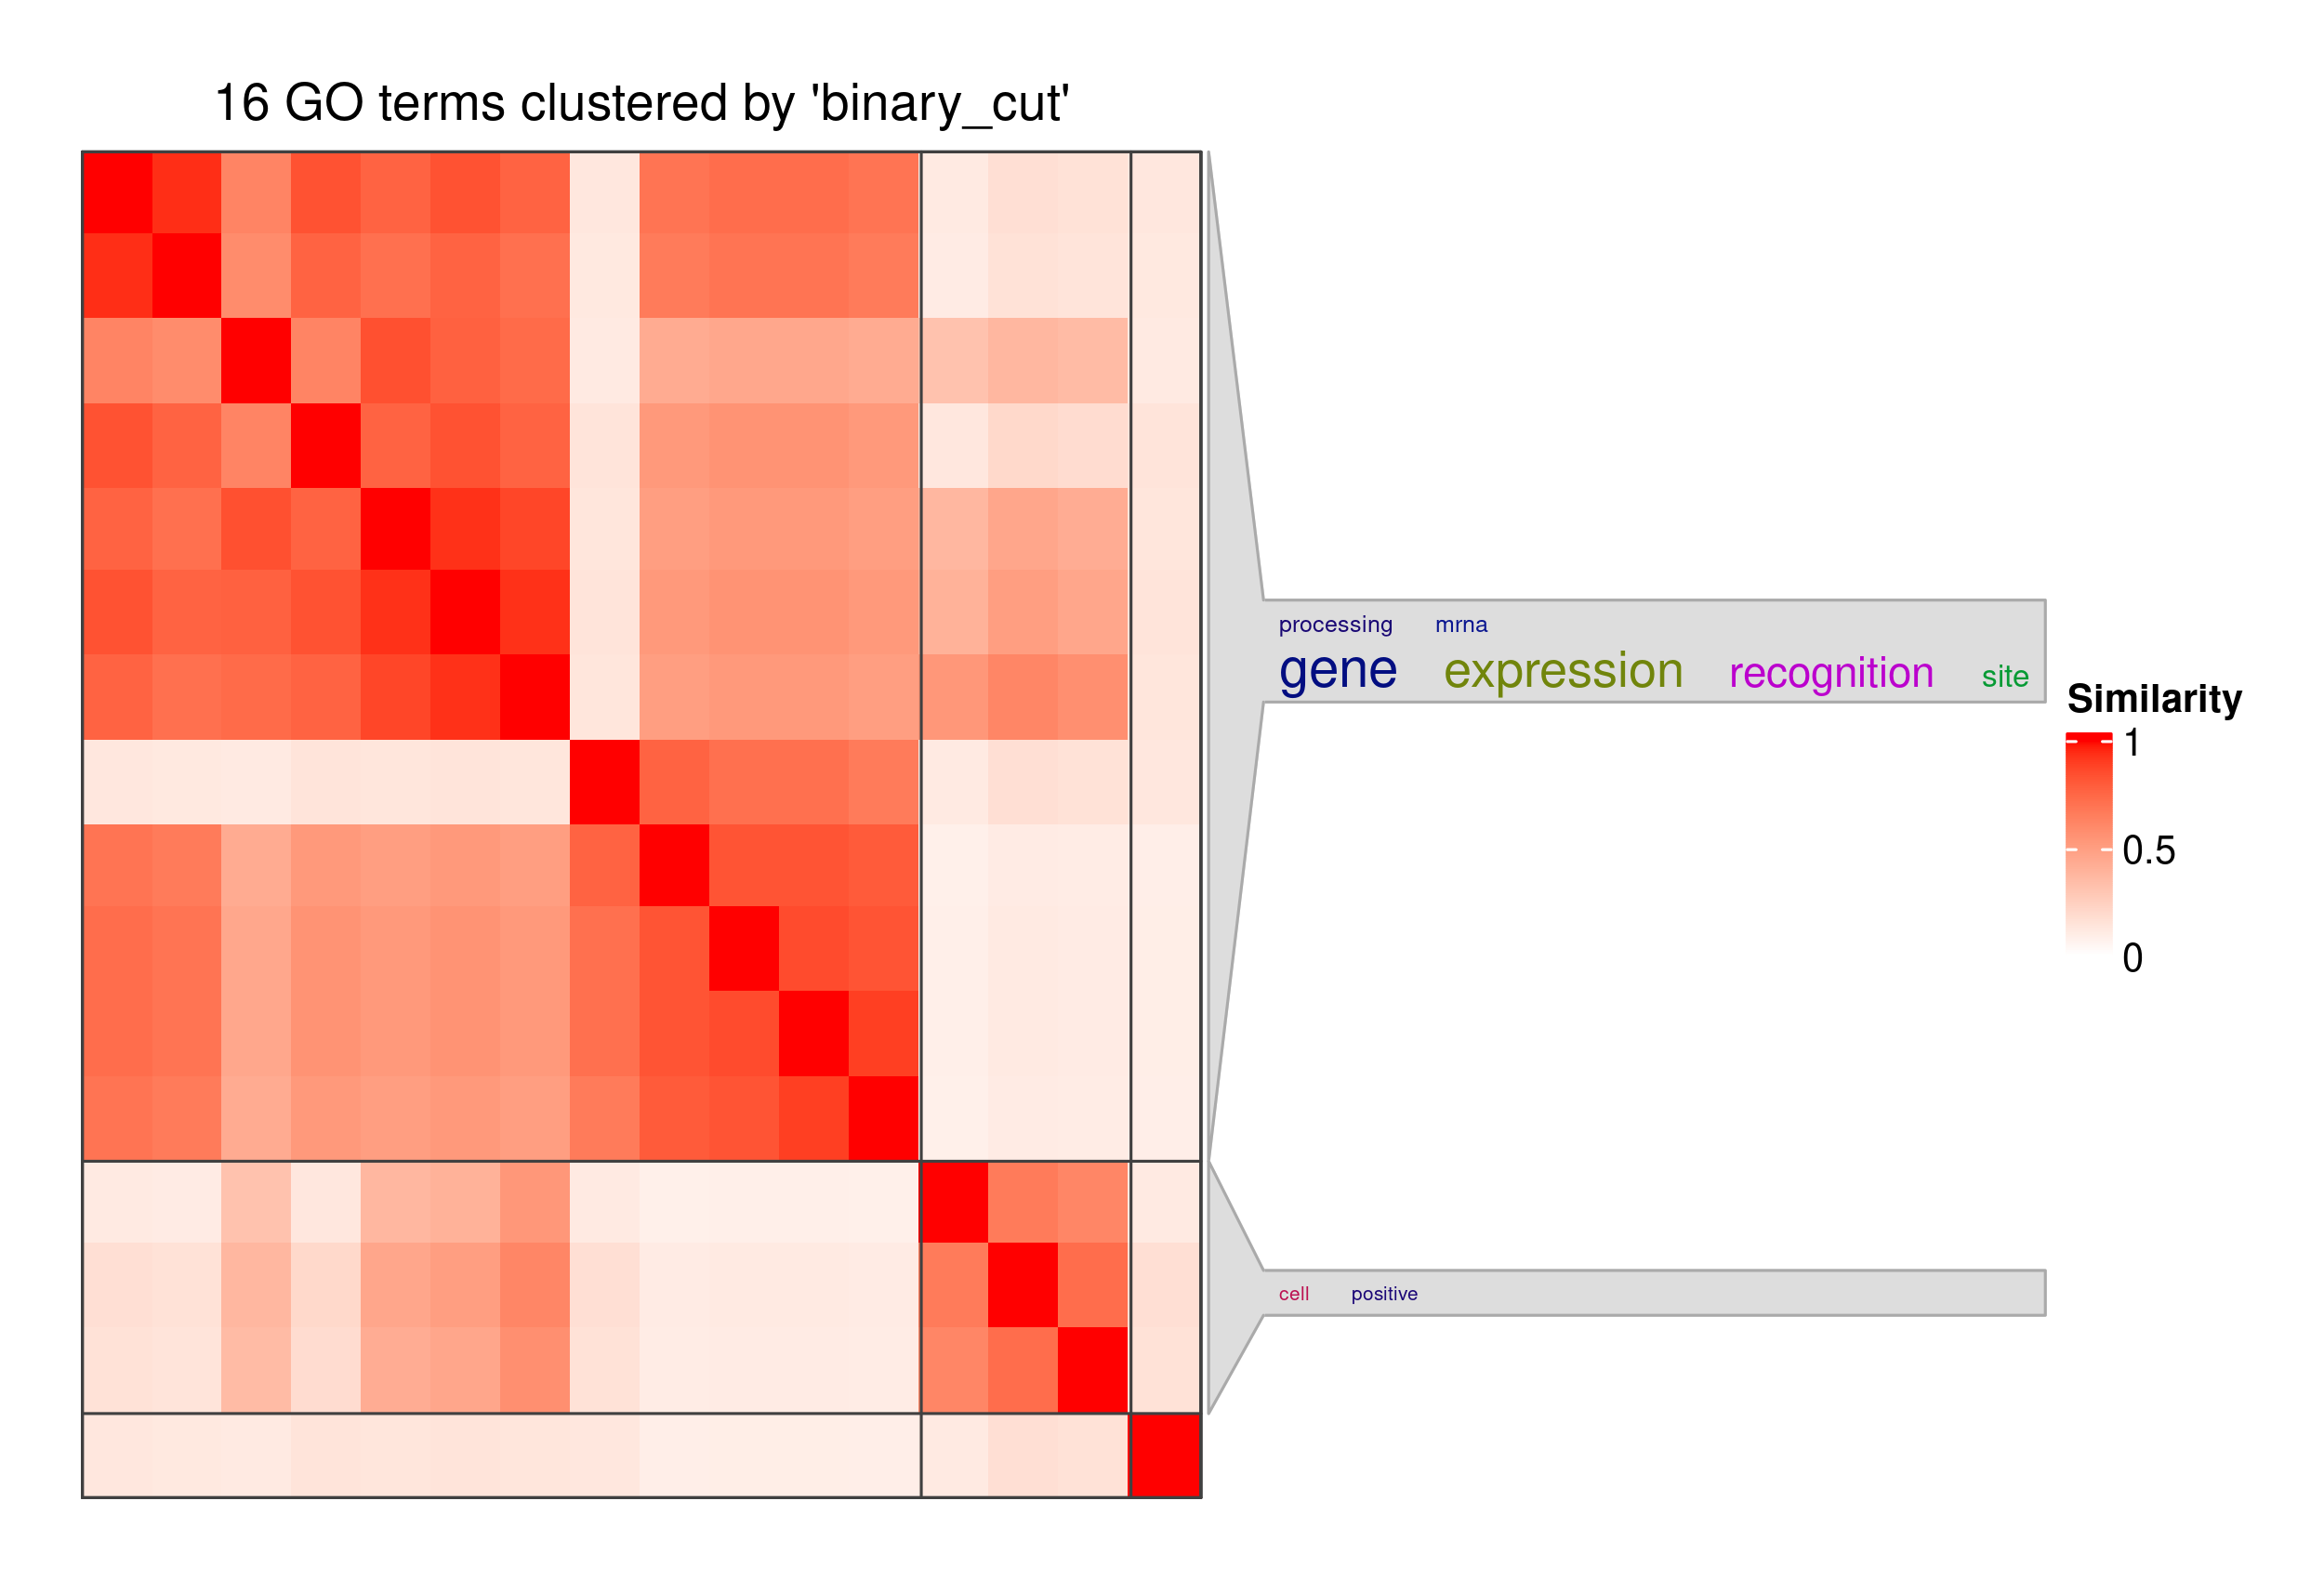

In [14]:
display(Image(filename="../../out/integrated_analysis/simona/up5p_lncrna_go_bp_simplifyGO.png"))

In [34]:
# check
chekc_bp_term = fantabio_up5p_all_lncRNA_quickgo_select.filter(
    pl.col("GO NAME").str.contains("positive regulation of stem cell proliferation")
)

pl.Config.set_tbl_rows(10)
display(chekc_bp_term)

transcript_id,RNACentral_ID,HN2,cre_id,GENE PRODUCT DB,QUALIFIER,GO ASPECT,GO TERM,GO NAME,ECO ID,GO EVIDENCE CODE,REFERENCE,WITH/FROM,ASSIGNED BY,DATE
str,str,i64,str,str,str,str,str,str,str,str,str,str,str,i64
"""ENST00000839036.1""","""URS0002A1A3A3""",53,"""FCHS_398765""","""RNAcentral""","""involved_in""","""P""","""GO:2000648""","""positive regulation of stem cell proliferation""","""ECO:0000256""","""IEA""","""GO_REF:0000115""","""Rfam:RF00736""","""RNAcentral""",20260727
"""ENST00000839036.1""","""URS0002A1A3A3""",53,"""FCHS_398766""","""RNAcentral""","""involved_in""","""P""","""GO:2000648""","""positive regulation of stem cell proliferation""","""ECO:0000256""","""IEA""","""GO_REF:0000115""","""Rfam:RF00736""","""RNAcentral""",20260727
"""ENST00000839036.1""","""URS0002A1A3A3""",53,"""FCHS_398767""","""RNAcentral""","""involved_in""","""P""","""GO:2000648""","""positive regulation of stem cell proliferation""","""ECO:0000256""","""IEA""","""GO_REF:0000115""","""Rfam:RF00736""","""RNAcentral""",20260727


&nbsp;

&nbsp;

&nbsp;

&nbsp;

# Molecular function (GO ASPECT = F)

### 1) Get Gene Ontology DAG and term similarity


In [16]:
%%R -i go_ids_mf
go_ids_mf <- as.character(go_ids_mf)

dag_mf <- create_ontology_DAG_from_GO_db(
  "MF",
  relations = c("part of", "regulates")
)
print(dag_mf)

mat_mf <- term_sim(dag_mf, go_ids_mf, method = "Sim_WP_1994")
print(round(mat_mf, 3))

An ontology_DAG object:
  Source: GO MF / GO.db package 3.22.0 
  10155 terms / 12595 relations
  Root: GO:0003674 
  Terms: GO:0000006, GO:0000007, GO:0000009, GO:0000010, ...
  Max depth: 13 
  Avg number of parents: 1.24
  Avg number of children: 1.31
  Aspect ratio: 395.7:1 (based on the longest distance from root)
                546.62:1 (based on the shortest distance from root)
  Relations: is_a, part_of

With the following columns in the metadata data frame:
  id, name, definition
           GO:0003735 GO:0004526 GO:0030533 GO:0030621 GO:0030627 GO:0045131
GO:0003735          1          0        0.0        0.0        0.0        0.0
GO:0004526          0          1        0.0        0.0        0.0        0.0
GO:0030533          0          0        1.0        0.6        0.6        0.6
GO:0030621          0          0        0.6        1.0        0.6        0.6
GO:0030627          0          0        0.6        0.6        1.0        0.8
GO:0045131          0          0        0.6

In [17]:
%%R
png(
  "../../out/integrated_analysis/simona/up5p_lncrna_go_mf_simplifyGO.png",
  width = 2300,
  height = 1700,
  res = 300
)
df_mf <- simplifyGO(
  mat_mf,
  verbose = FALSE,
  padding = unit(c(7.5, 7.5, 7.5, 7.5), "mm"),
  word_cloud_grob_param = list(
    fontsize = c(15, 25),
    max_width = 70,
    word_space = 6
  )
)
invisible(dev.off())

meta_mf <- as.data.frame(mcols(dag_mf)[, c("id", "name")])
print(merge(df_mf, meta_mf, by = "id"))

          id cluster                                      name
1 GO:0003735       1        structural constituent of ribosome
2 GO:0004526       2                   ribonuclease P activity
3 GO:0030533       3 triplet codon-amino acid adaptor activity
4 GO:0030621       3                          U4 snRNA binding
5 GO:0030627       3           pre-mRNA 5'-splice site binding
6 GO:0045131       3             pre-mRNA branch point binding


Perform keywords enrichment for 3 GO lists...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...


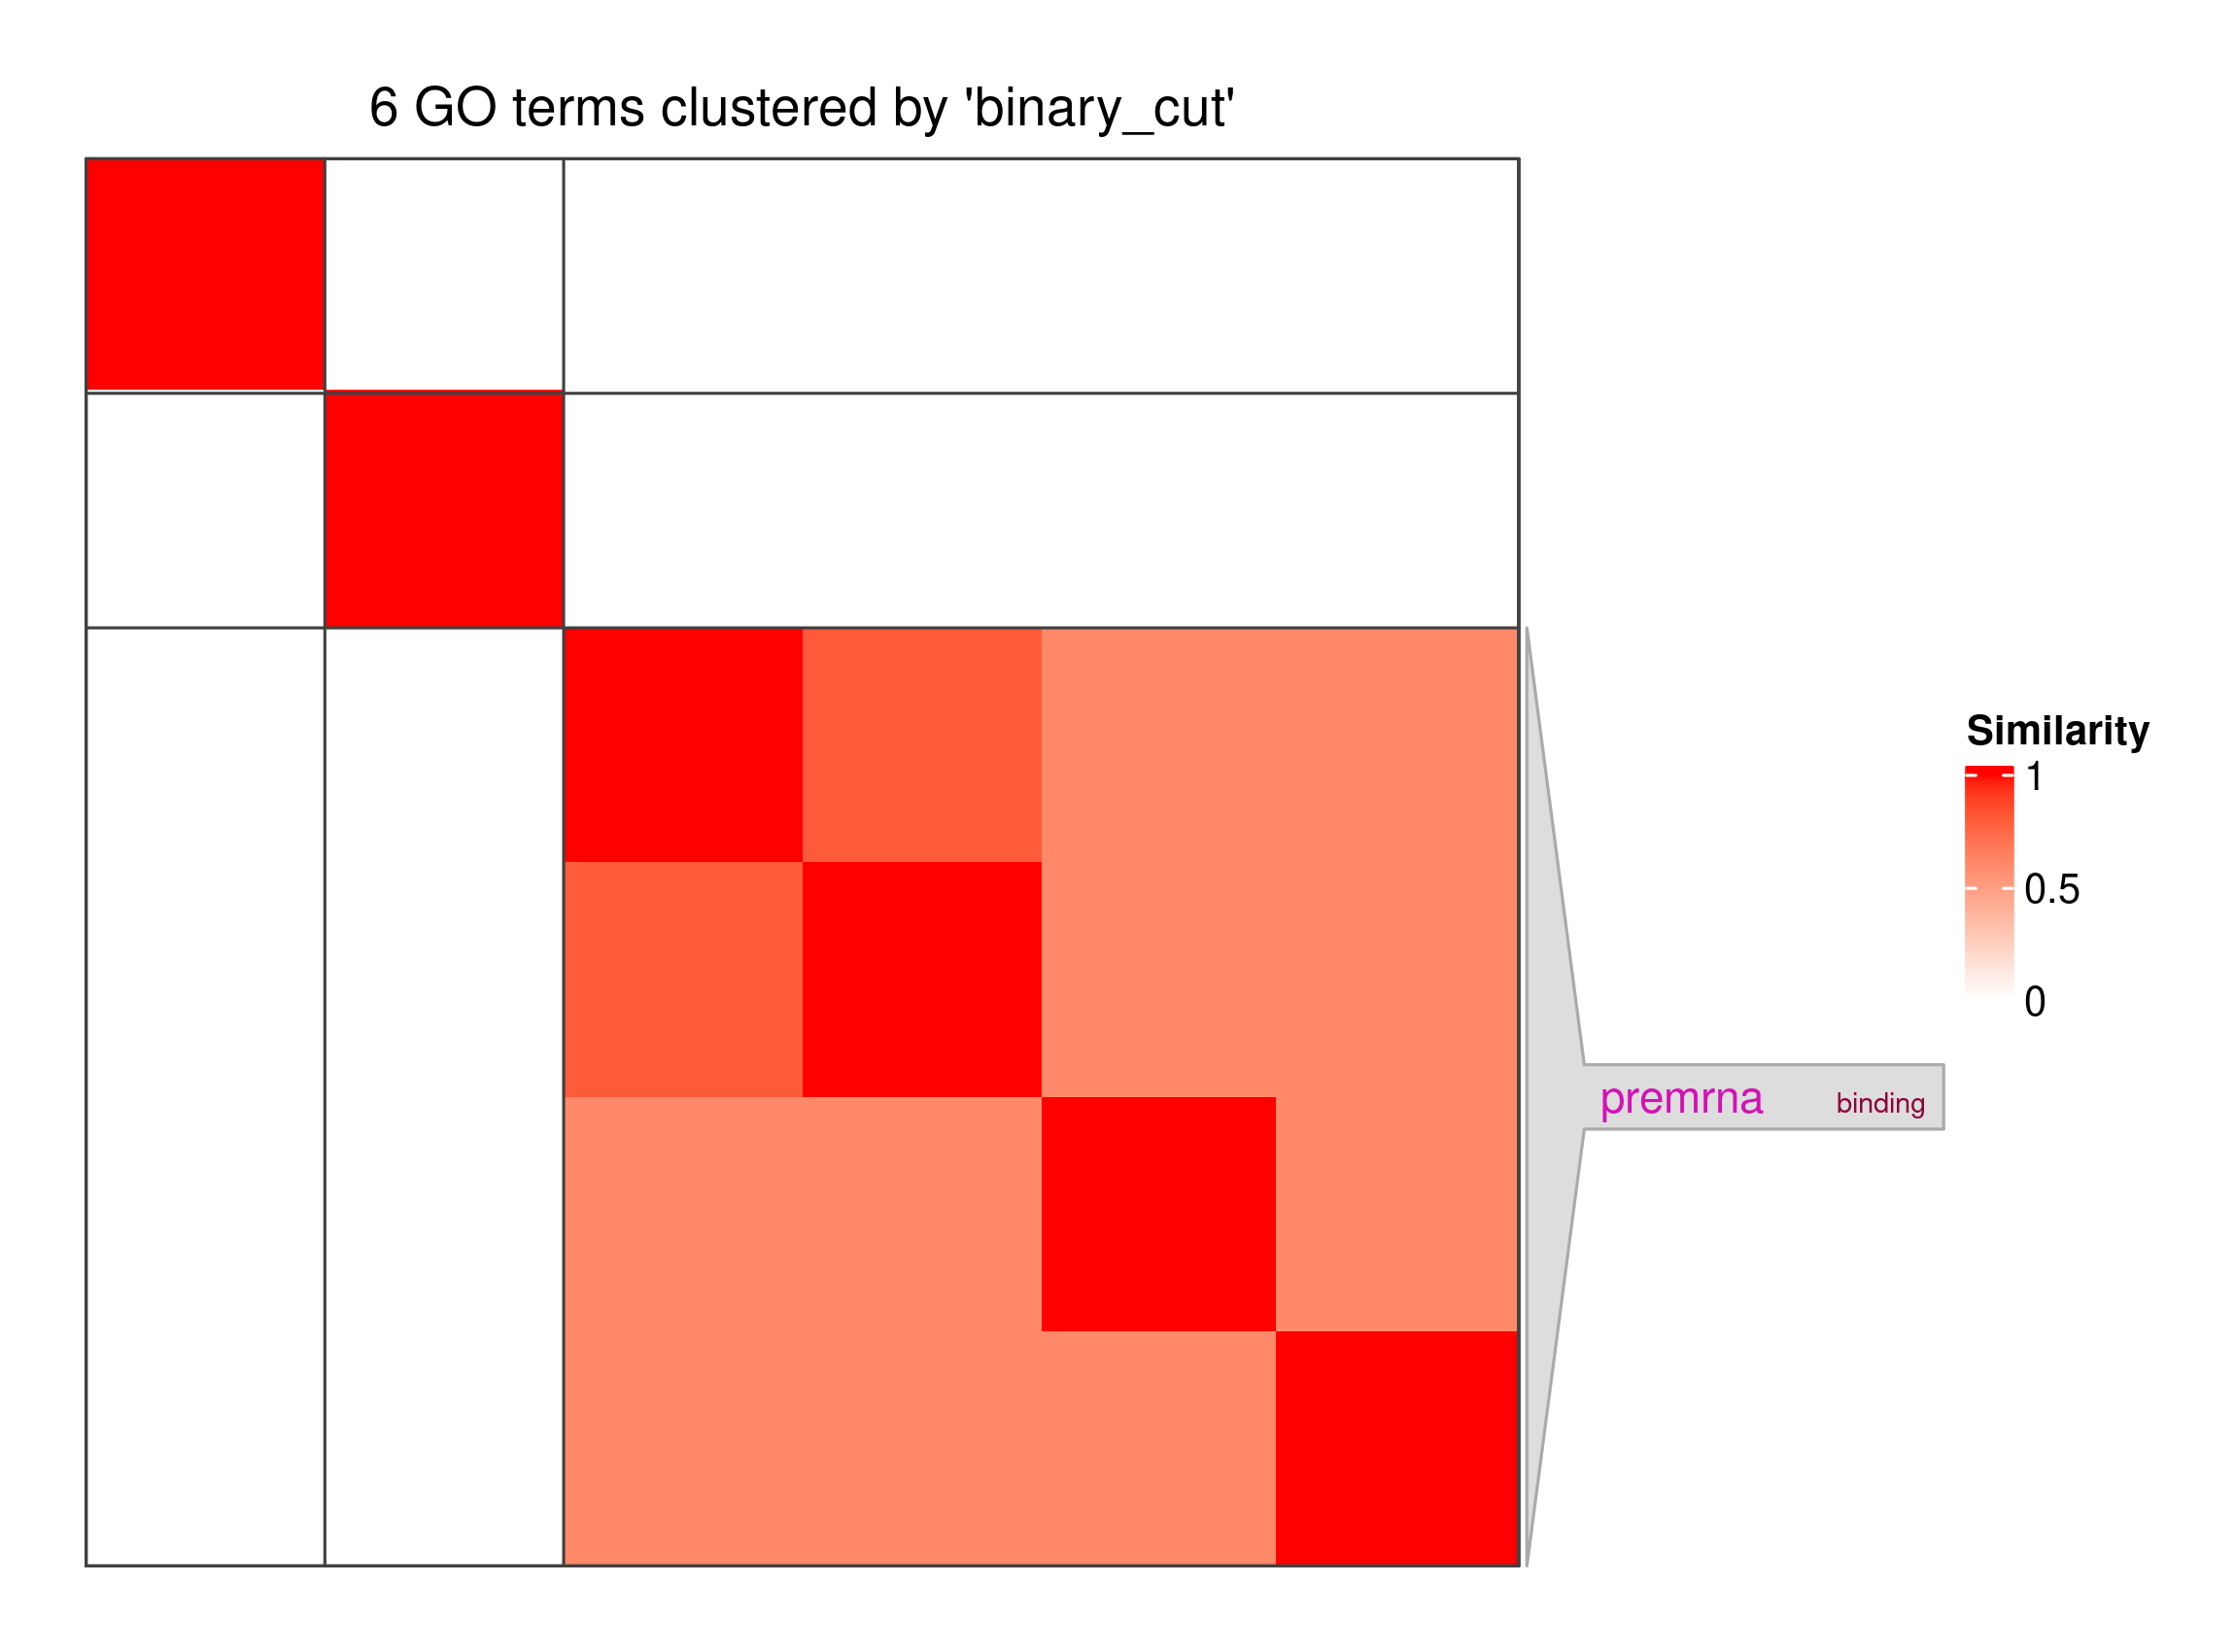

In [18]:
display(Image(filename="../../out/integrated_analysis/simona/up5p_lncrna_go_mf_simplifyGO.png"))

&nbsp;

&nbsp;

&nbsp;

&nbsp;

# Cellular component (GO ASPECT = C)

### 1) Get Gene Ontology DAG and term similarity


In [19]:
%%R -i go_ids_cc
go_ids_cc <- as.character(go_ids_cc)

dag_cc <- create_ontology_DAG_from_GO_db(
  "CC",
  relations = c("part of", "regulates")
)
print(dag_cc)

mat_cc <- term_sim(dag_cc, go_ids_cc, method = "Sim_WP_1994")
print(round(mat_cc, 3))

An ontology_DAG object:
  Source: GO CC / GO.db package 3.22.0 
  4052 terms / 6457 relations
  Root: GO:0005575 
  Terms: GO:0000015, GO:0000109, GO:0000110, GO:0000111, ...
  Max depth: 14 
  Avg number of parents: 1.59
  Avg number of children: 1.65
  Aspect ratio: 58.64:1 (based on the longest distance from root)
                168.86:1 (based on the shortest distance from root)
  Relations: is_a, part_of

With the following columns in the metadata data frame:
  id, name, definition
           GO:0005634 GO:0005682 GO:0005685 GO:0005688 GO:0005693 GO:0005730
GO:0005634      1.000      0.714      0.714      0.714      0.714      0.833
GO:0005682      0.714      1.000      0.889      0.889      0.889      0.625
GO:0005685      0.714      0.889      1.000      0.889      0.889      0.625
GO:0005688      0.714      0.889      0.889      1.000      0.889      0.625
GO:0005693      0.714      0.889      0.889      0.889      1.000      0.625
GO:0005730      0.833      0.625      0.625  

In [20]:
%%R
png(
  "../../out/integrated_analysis/simona/up5p_lncrna_go_cc_simplifyGO.png",
  width = 2300,
  height = 1700,
  res = 300
)
df_cc <- simplifyGO(
  mat_cc,
  verbose = FALSE,
  padding = unit(c(7.5, 7.5, 7.5, 7.5), "mm"),
  word_cloud_grob_param = list(
    fontsize = c(15, 25),
    max_width = 70,
    word_space = 6
  )
)
invisible(dev.off())

meta_cc <- as.data.frame(mcols(dag_cc)[, c("id", "name")])
print(merge(df_cc, meta_cc, by = "id"))

           id cluster
1  GO:0005634       1
2  GO:0005682       1
3  GO:0005685       1
4  GO:0005688       1
5  GO:0005693       1
6  GO:0005730       1
7  GO:0005737       1
8  GO:0005786       1
9  GO:0005840       1
10 GO:0015030       1
11 GO:0016442       1
12 GO:0030677       1
13 GO:0046540       1
                                                           name
1                                                       nucleus
2                                                      U5 snRNP
3                                                      U1 snRNP
4                                                      U6 snRNP
5                                                     U12 snRNP
6                                                     nucleolus
7                                                     cytoplasm
8  signal recognition particle, endoplasmic reticulum targeting
9                                                      ribosome
10                                                  

Perform keywords enrichment for 1 GO lists...
keyword enrichment, 3259/3259...


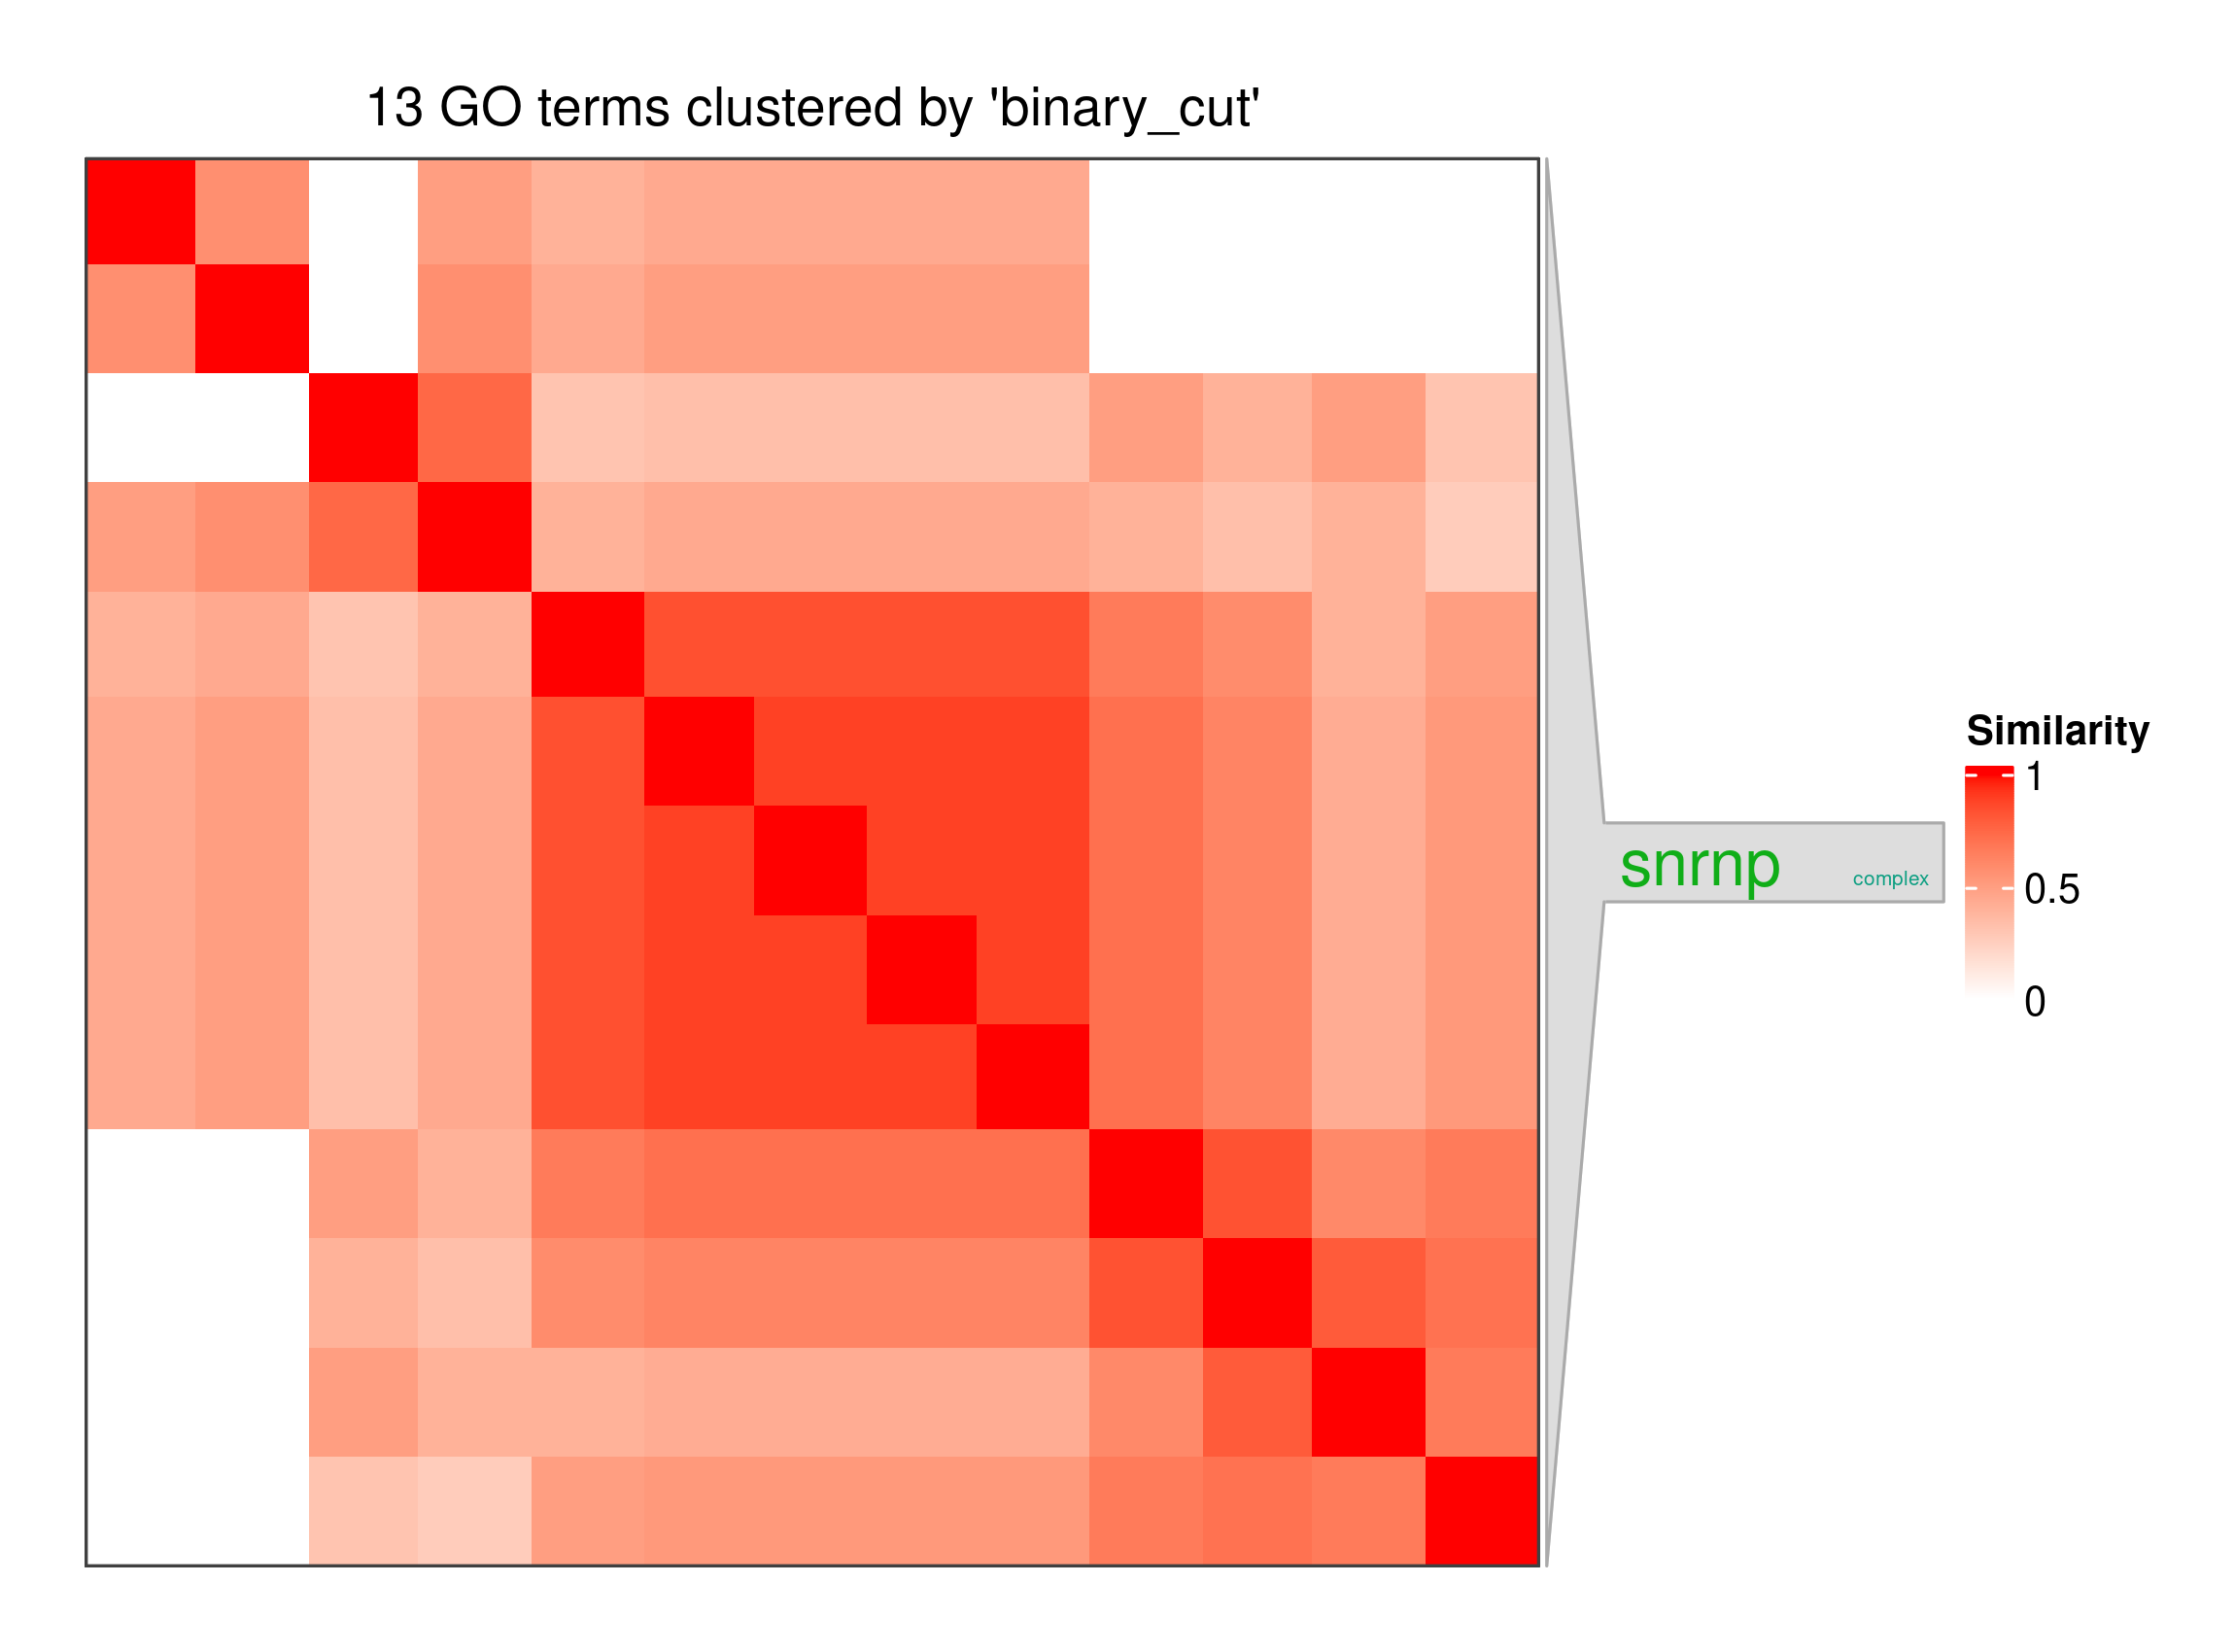

In [21]:
display(Image(filename="../../out/integrated_analysis/simona/up5p_lncrna_go_cc_simplifyGO.png"))

In [22]:
# check
nucleolus = fantabio_up5p_all_lncRNA_quickgo_select.filter(
    pl.col("GO NAME") == "Cajal body"
)

display(nucleolus)

transcript_id,RNACentral_ID,HN2,cre_id,GENE PRODUCT DB,QUALIFIER,GO ASPECT,GO TERM,GO NAME,ECO ID,GO EVIDENCE CODE,REFERENCE,WITH/FROM,ASSIGNED BY,DATE
str,str,i64,str,str,str,str,str,str,str,str,str,str,str,i64
"""ENST00000544685.4""","""URS0002A2B4F4""",95,"""FCHS_143957""","""RNAcentral""","""located_in""","""C""","""GO:0015030""","""Cajal body""","""ECO:0000256""","""IEA""","""GO_REF:0000115""","""Rfam:RF00426""","""RNAcentral""",20260727
"""ENST00000544685.4""","""URS0002A2B4F4""",95,"""FCHS_143958""","""RNAcentral""","""located_in""","""C""","""GO:0015030""","""Cajal body""","""ECO:0000256""","""IEA""","""GO_REF:0000115""","""Rfam:RF00426""","""RNAcentral""",20260727


&nbsp;

&nbsp;

&nbsp;

&nbsp;

# (Experimental) Transcript-level group similarity

- GO term 数が少ない（BP 17 / MF 7 / CC 14）ため、各 lncRNA transcript を **GO term の集合** とみなして `group_sim()` も計算する
- method は `GroupSim_pairwise_BMA`、内部の term similarity は `Sim_WP_1994`
- 共通する Rfam のエントリーに由来する複数の GO term があるので、あくまで参考程度にしておく

In [23]:
# One row per transcript x GO term; CRE duplication is dropped
annot_by_aspect = {}
for aspect in ("P", "F", "C"):
    annot_by_aspect[aspect] = (
        fantabio_up5p_all_lncRNA_quickgo_select
        .filter(pl.col("GO ASPECT") == aspect)
        .select("transcript_id", pl.col("GO TERM").alias("GO_TERM"))
        .unique()
        .sort(["transcript_id", "GO_TERM"])
        .to_pandas()
    )
    print(aspect, annot_by_aspect[aspect].shape)

annot_bp = annot_by_aspect["P"]
annot_mf = annot_by_aspect["F"]
annot_cc = annot_by_aspect["C"]

P (78, 2)
F (34, 2)
C (61, 2)


In [24]:
%%R
# Pairwise BMA group similarity for transcripts, then ComplexHeatmap
transcript_group_sim <- function(dag, annot, png_path, column_title) {
  go_list <- split(as.character(annot$GO_TERM), as.character(annot$transcript_id))
  ids <- names(go_list)
  n <- length(go_list)
  mat <- matrix(NA_real_, n, n, dimnames = list(ids, ids))
  for (i in seq_len(n)) {
    for (j in i:n) {
      s <- group_sim(
        dag,
        go_list[[i]],
        go_list[[j]],
        method = "GroupSim_pairwise_BMA",
        control = list(term_sim_method = "Sim_WP_1994")
      )
      mat[i, j] <- s
      mat[j, i] <- s
    }
  }
  png(png_path, width = 2200, height = 2000, res = 300)
  ht <- Heatmap(
    mat,
    name = "BMA",
    column_title = column_title,
    show_row_names = TRUE,
    show_column_names = FALSE,
    row_names_gp = gpar(fontsize = 5)
  )
  draw(ht)
  invisible(dev.off())
  invisible(mat)
}

&nbsp;

&nbsp;

&nbsp;

&nbsp;

### Biological Process (BP)

In [25]:
%%R -i annot_bp
mat_tx_bp <- transcript_group_sim(
  dag_bp,
  annot_bp,
  "../../out/integrated_analysis/simona/up5p_lncrna_tx_bp_group_sim.png",
  sprintf("BP transcript group similarity (n = %s)", nrow(unique(annot_bp["transcript_id"])))
)

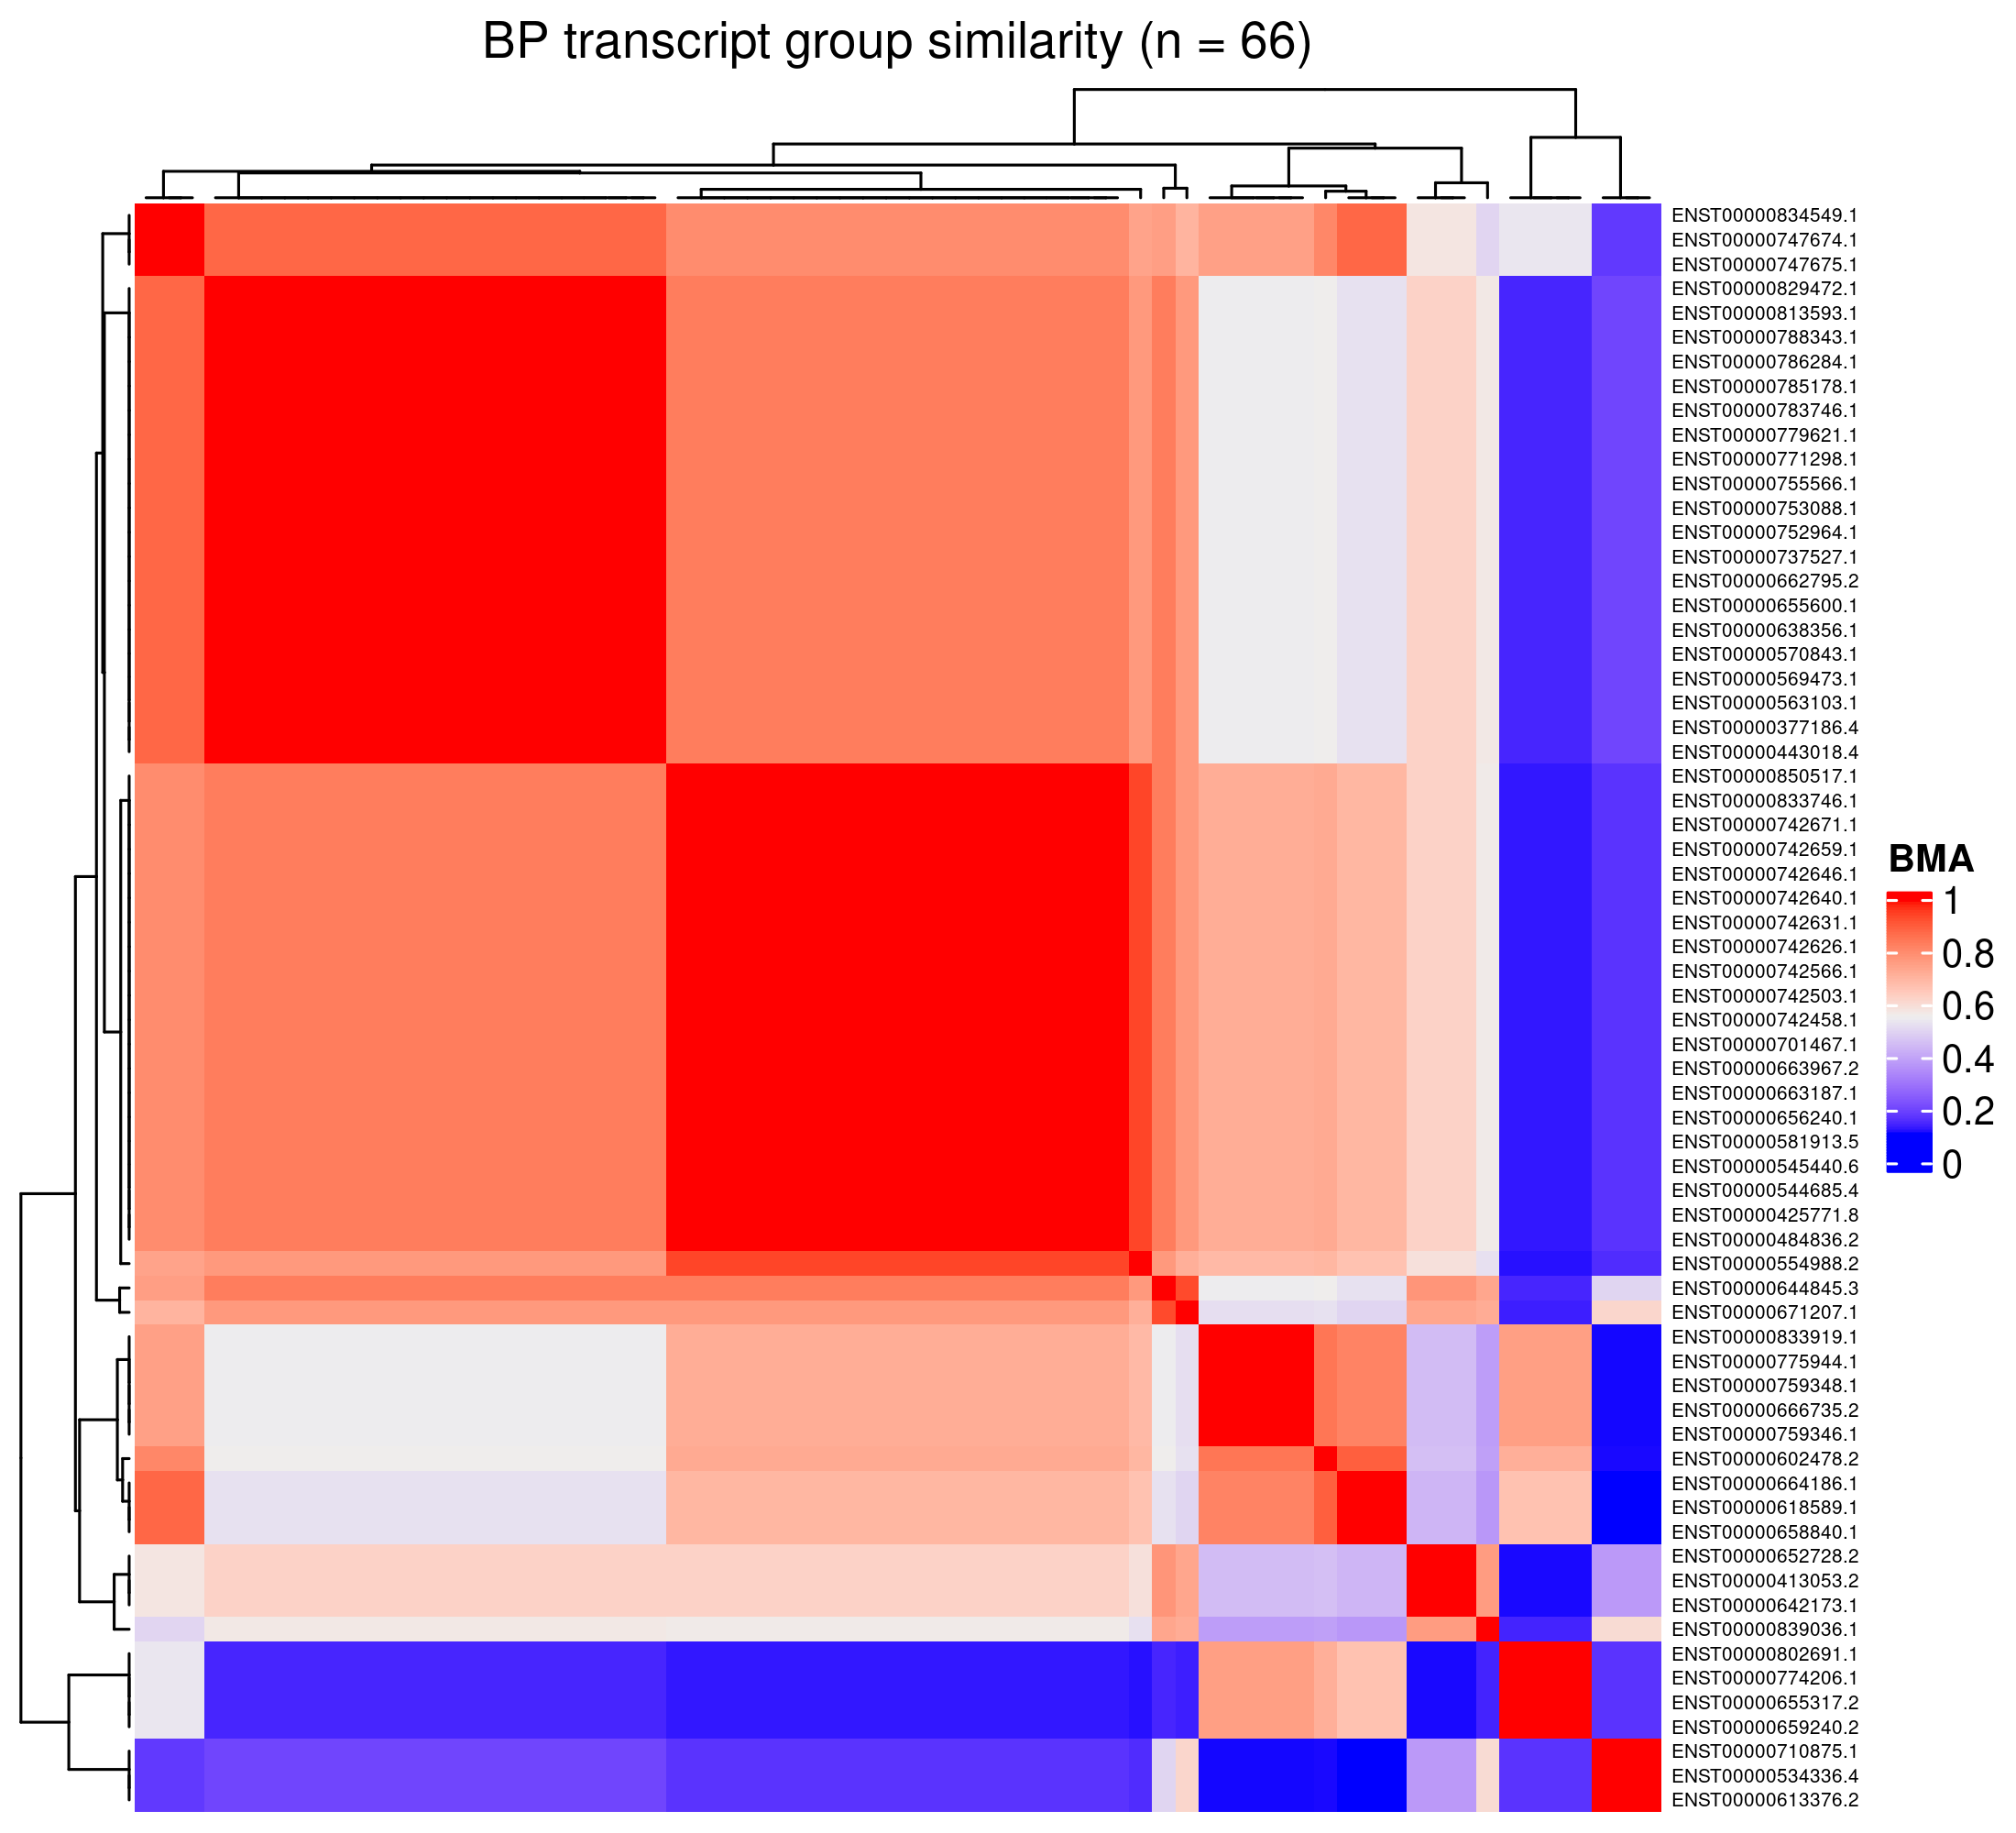

In [26]:
display(Image(filename="../../out/integrated_analysis/simona/up5p_lncrna_tx_bp_group_sim.png"))

&nbsp;

&nbsp;

&nbsp;

&nbsp;

### Molecular Function (MF)

In [27]:
%%R -i annot_mf
mat_tx_mf <- transcript_group_sim(
  dag_mf,
  annot_mf,
  "../../out/integrated_analysis/simona/up5p_lncrna_tx_mf_group_sim.png",
  sprintf("MF transcript group similarity (n = %s)", nrow(unique(annot_mf["transcript_id"])))
)

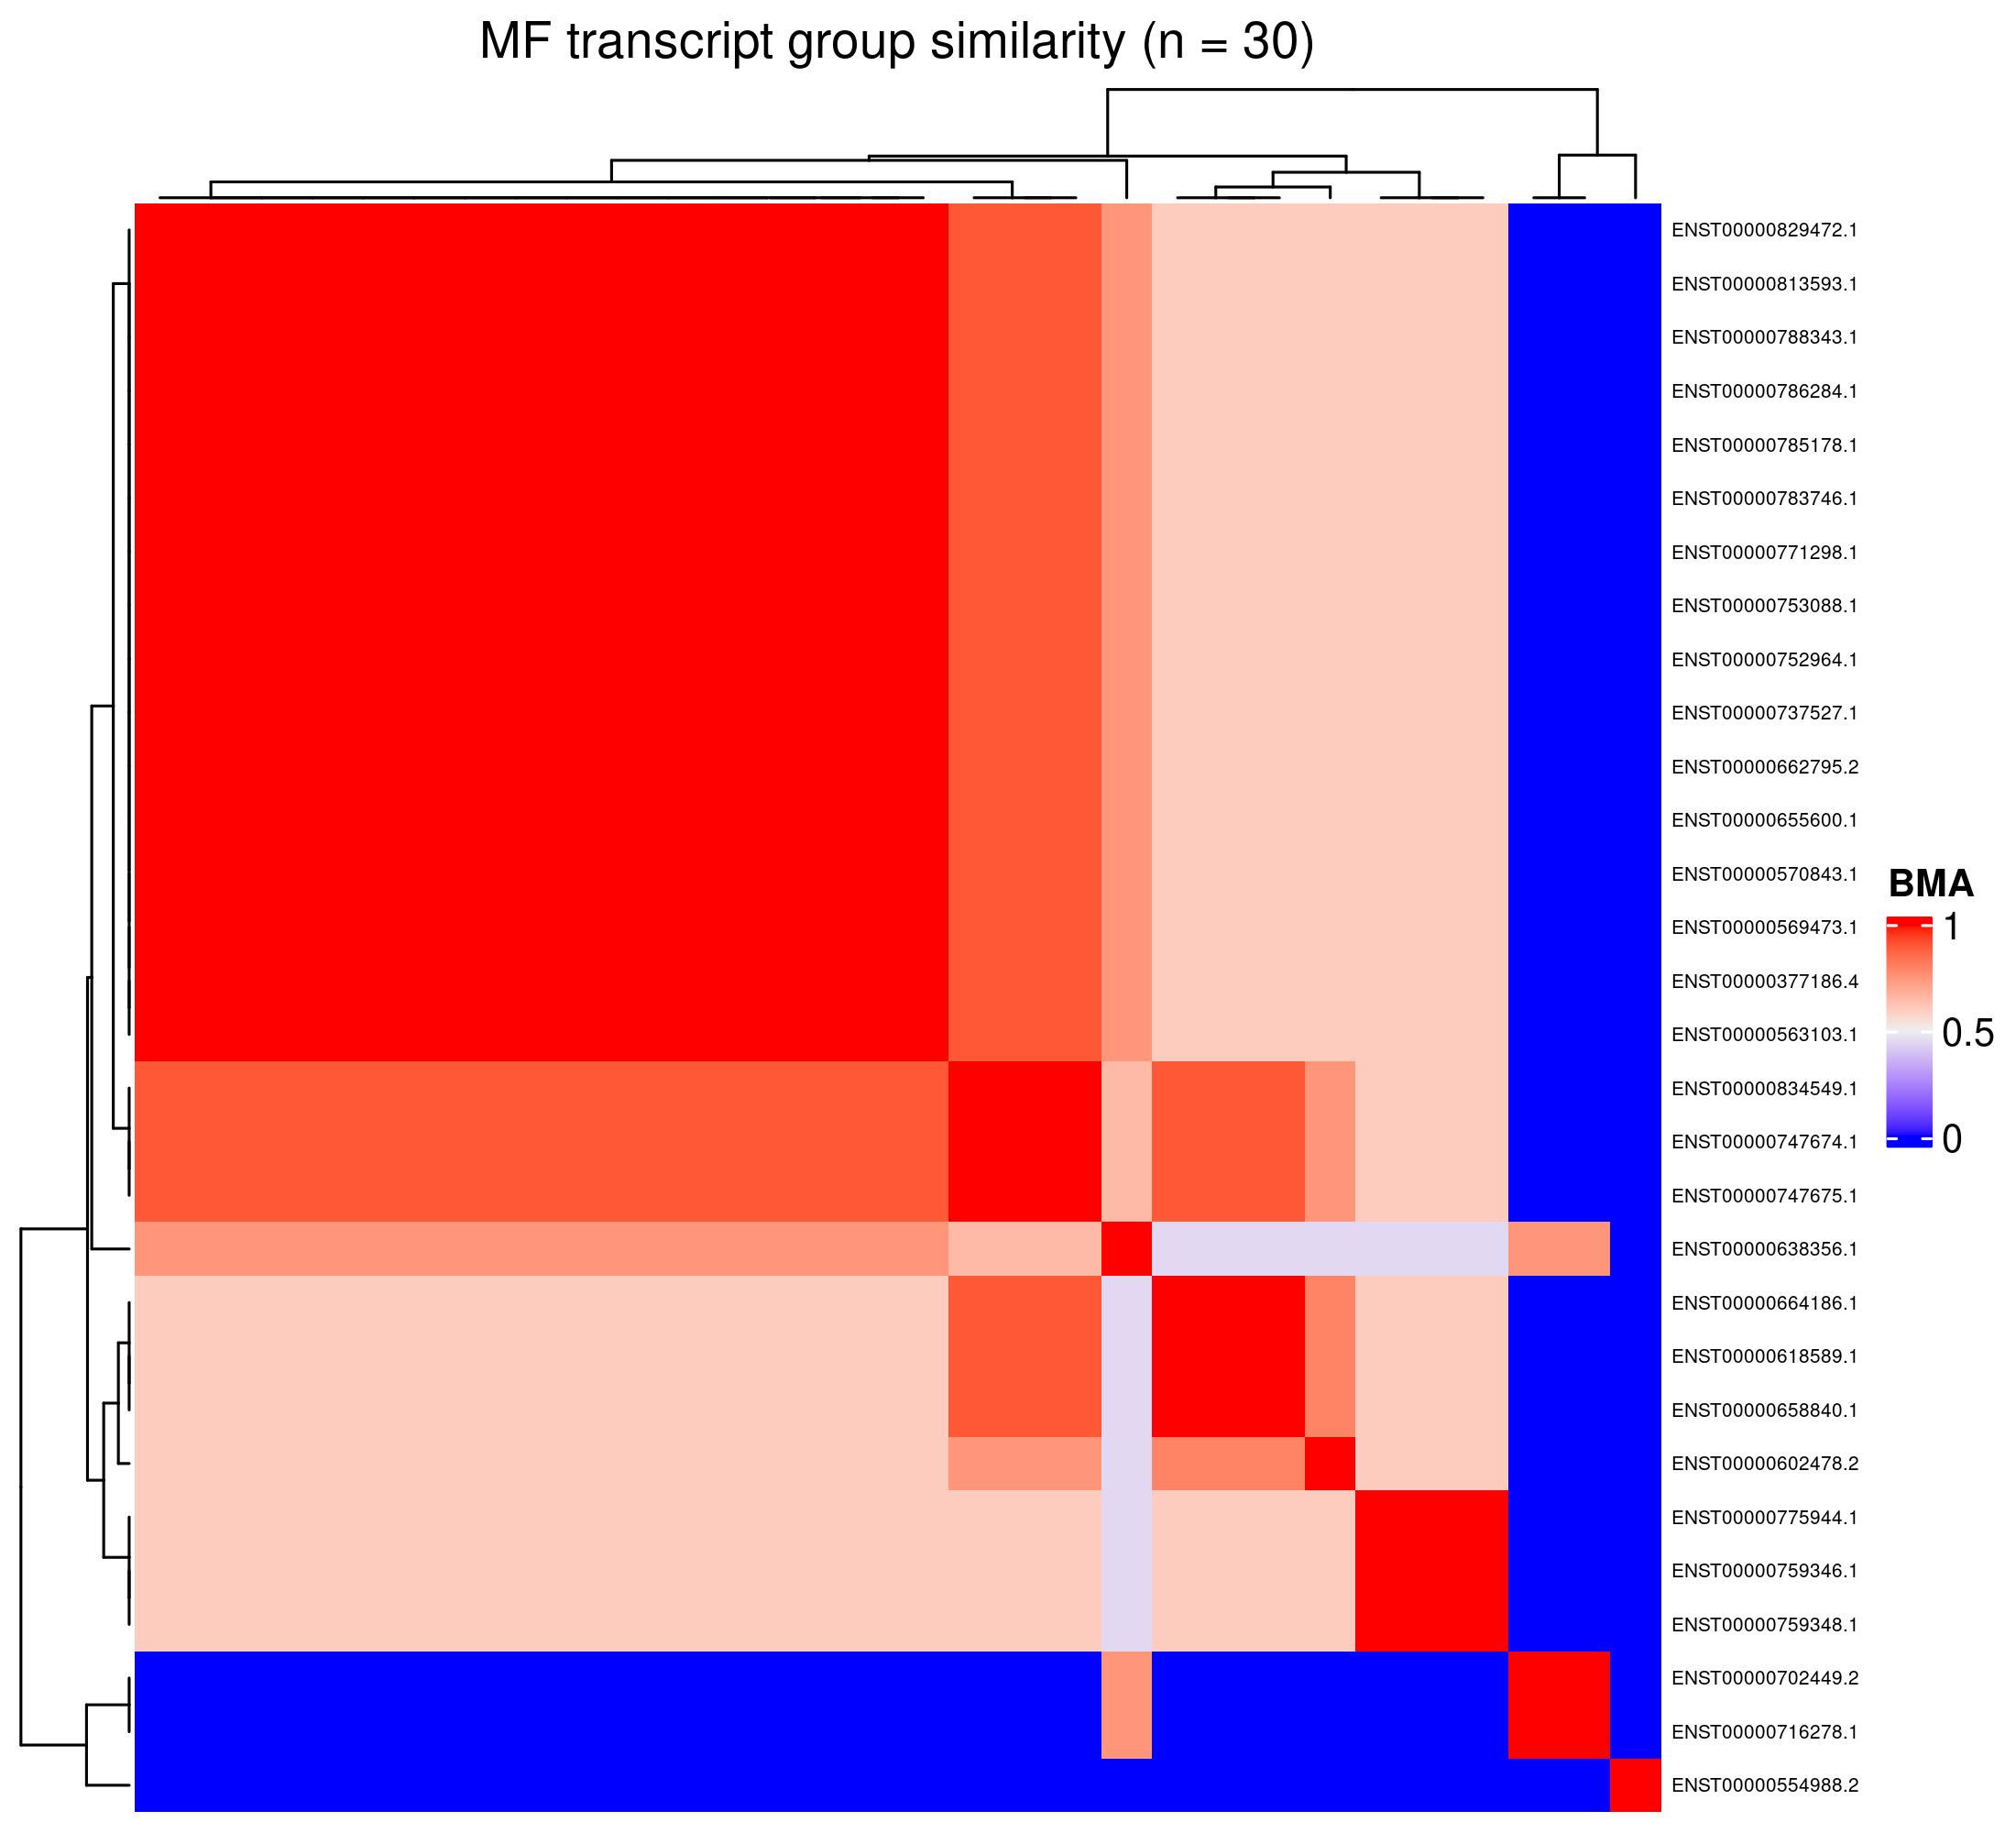

In [28]:
display(Image(filename="../../out/integrated_analysis/simona/up5p_lncrna_tx_mf_group_sim.png"))

&nbsp;

&nbsp;

&nbsp;

&nbsp;

### Cellular Component (CC)

In [29]:
%%R -i annot_cc
mat_tx_cc <- transcript_group_sim(
  dag_cc,
  annot_cc,
  "../../out/integrated_analysis/simona/up5p_lncrna_tx_cc_group_sim.png",
  sprintf("CC transcript group similarity (n = %s)", nrow(unique(annot_cc["transcript_id"])))
)

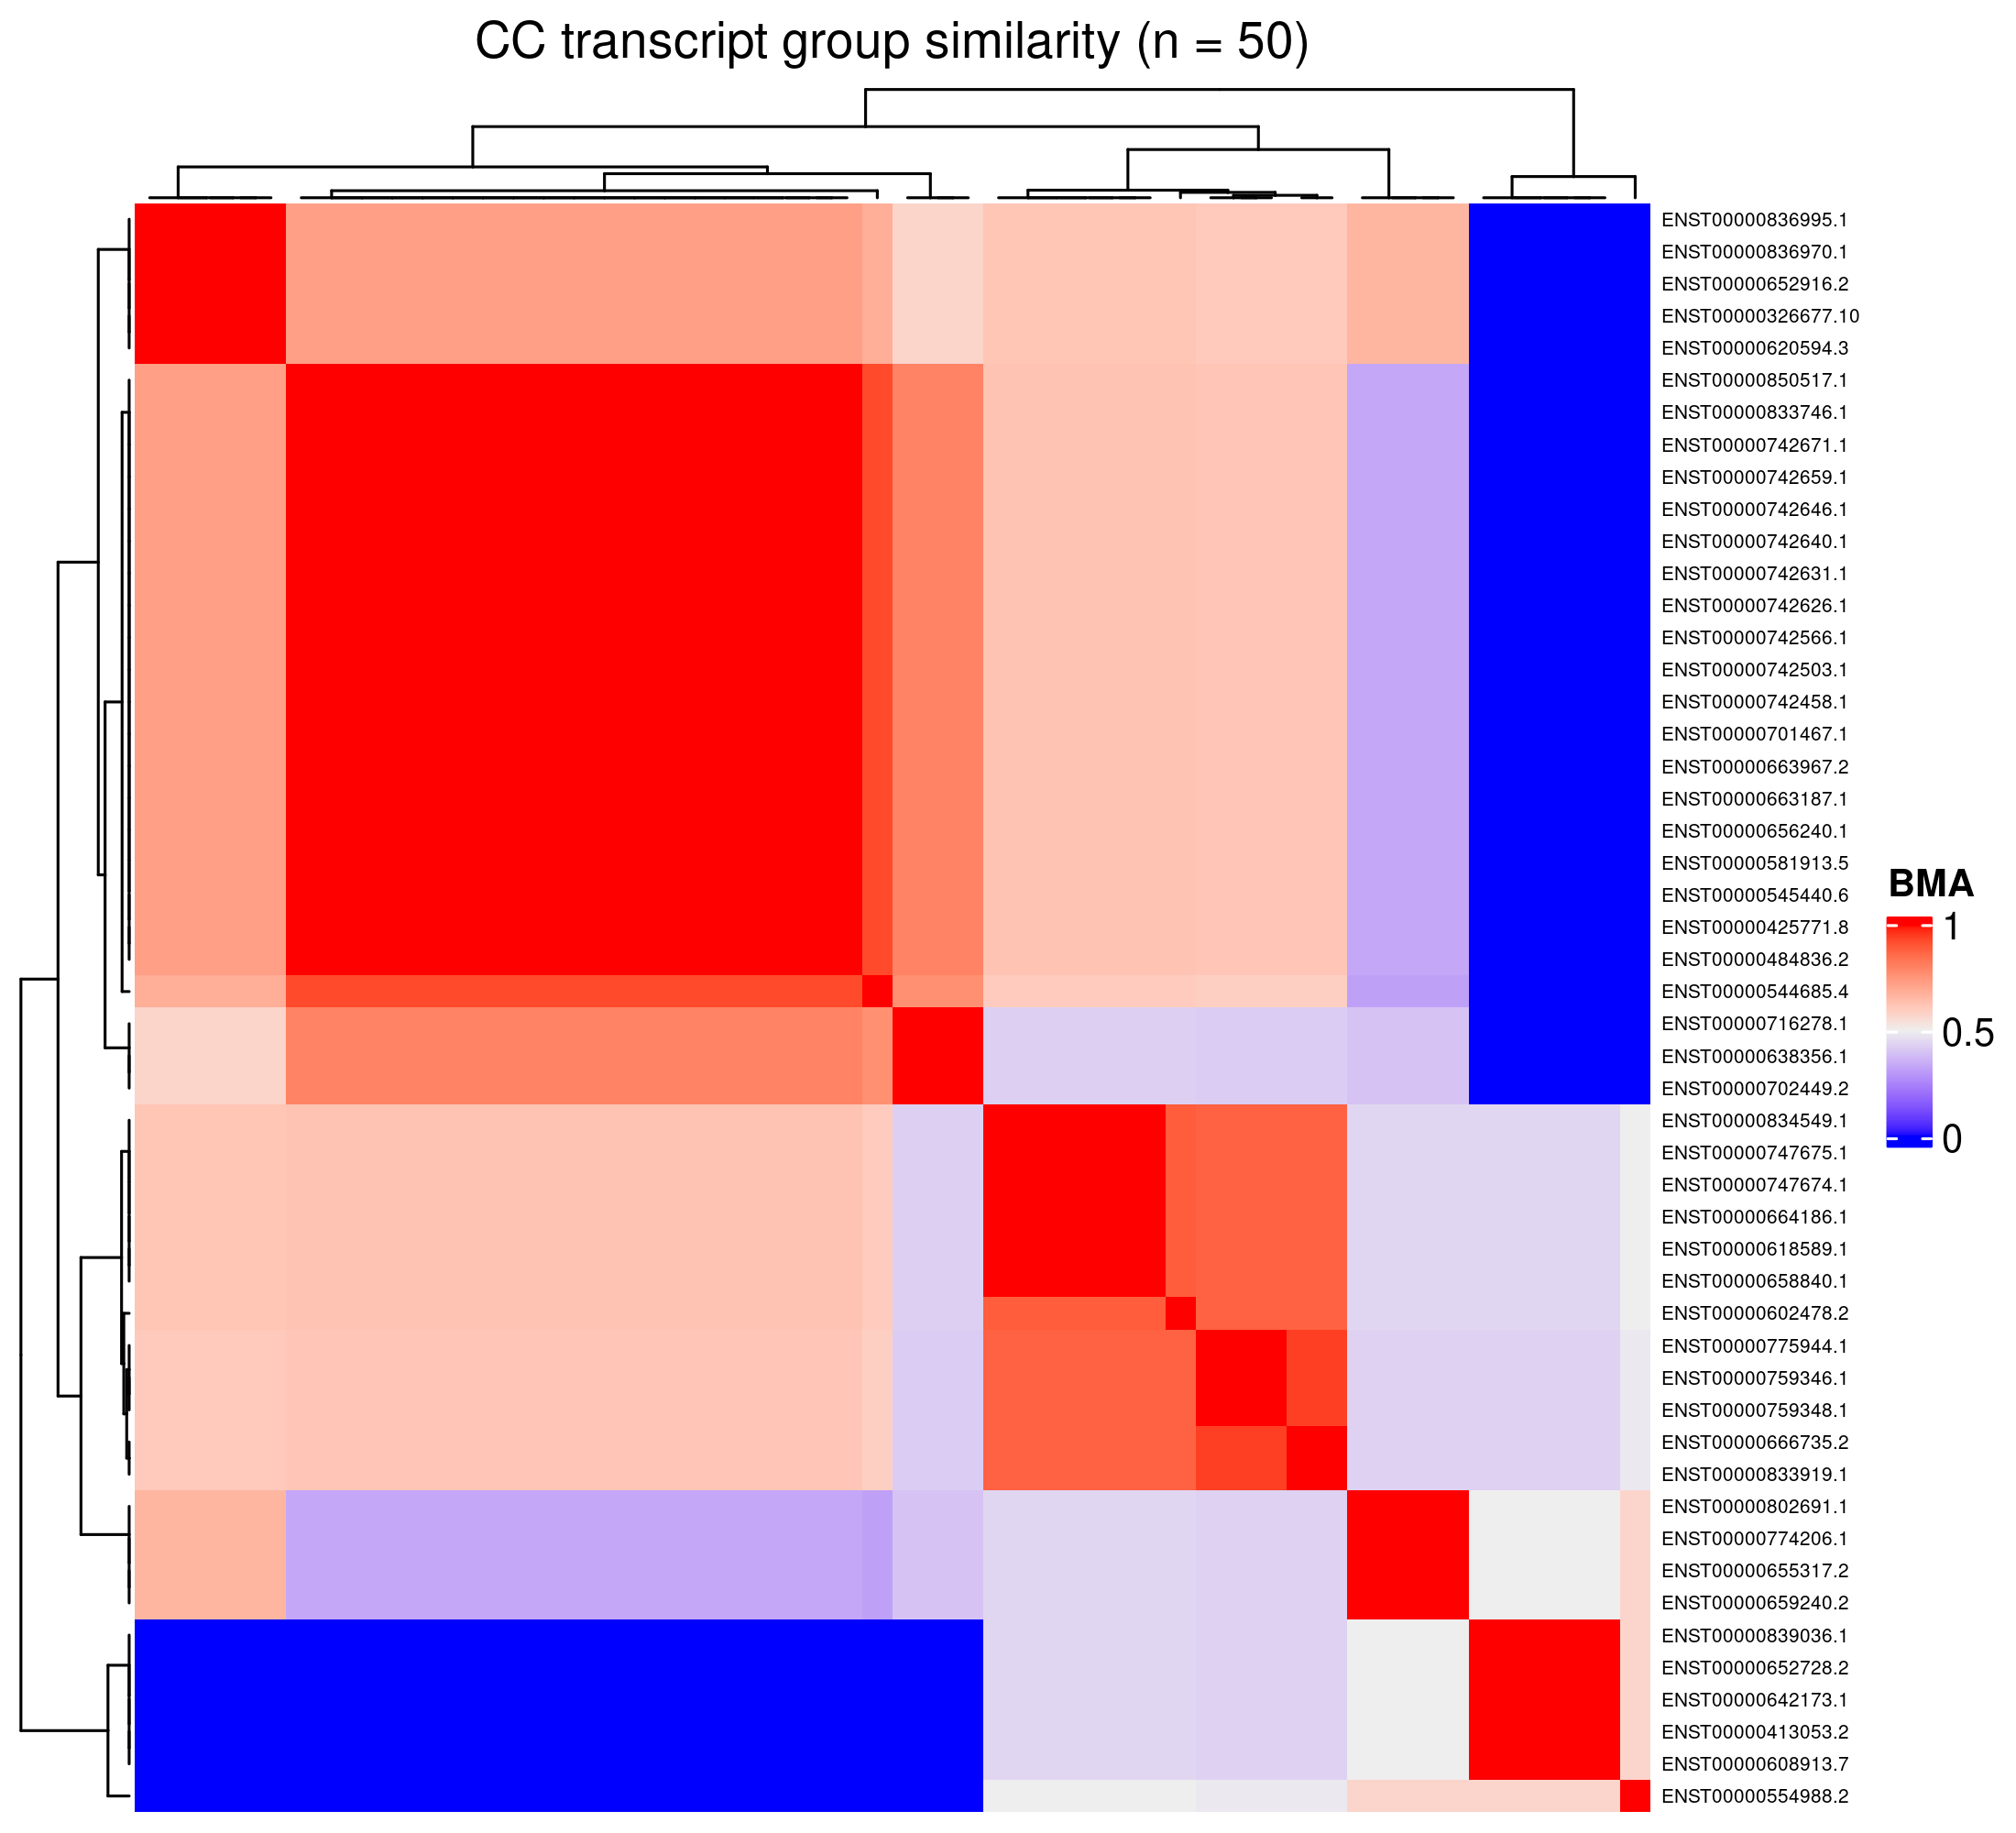

In [30]:
display(Image(filename="../../out/integrated_analysis/simona/up5p_lncrna_tx_cc_group_sim.png"))